In [1]:
CSV_FILE = r"C:\Users\ankit\Desktop\Mtech 1st Sem\PFCS\Honey pot\AWS_Honeypot_marx-geo.csv"  

# True = test fewer cluster numbers and run faster.
# False = test more cluster numbers and take longer.
FAST_MODE = True

# Risk >= this value is shown as an ALERT.
ALERT_RISK = 0.90

# Maximum number of IPs shown on the dashboard map.
MAX_MAP_POINTS = 4000

# Same random seed every time -> repeatable results.
RANDOM_STATE = 42

In [2]:
# 1. IMPORT LIBRARIES

import os
import json
import time
import ipaddress
import urllib.request
import threading
import http.server
import urllib.parse
import warnings
import webbrowser
import re

from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.ensemble import IsolationForest
from sklearn.decomposition import PCA

from sklearn.metrics import (
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_score
)

from IPython.display import display, IFrame

sns.set_theme(style="whitegrid")

In [3]:
# STEP 1 - LOAD AND CLEAN THE DATA

print("=" * 70)
print("STEP 1 - LOADING AND CLEANING DATA")
print("=" * 70)

# Use the one dataset selected above.
if not os.path.exists(CSV_FILE):
    csv_path = input("Enter the full path of your CSV file: ").strip()

    if not os.path.exists(csv_path):
        raise FileNotFoundError("CSV file was not found.")
else:
    csv_path = CSV_FILE


# Read CSV
raw = pd.read_csv(csv_path)

print("File:", csv_path)
print("Rows:", len(raw))
print("Columns:", len(raw.columns))


# Make a copy so the original loaded dataframe is not changed.
df = raw.copy()


# Remove unwanted columns such as "Unnamed: 15".
columns_to_remove = []

for column in df.columns:
    if column.startswith("Unnamed"):
        columns_to_remove.append(column)

if len(columns_to_remove) > 0:
    df = df.drop(columns=columns_to_remove)
    print("Removed:", columns_to_remove)


# Convert datetime to proper datetime format.
df["datetime"] = pd.to_datetime(
    df["datetime"],
    errors="coerce"
)

# Remove rows where datetime could not be read.
df = df.dropna(
    subset=["datetime"]
).copy()


# Mark repeated packets.
# True means this record is a duplicate of an earlier record
# using the selected network fields.
df["is_repeat"] = df.duplicated(
    subset=[
        "datetime",
        "host",
        "srcstr",
        "proto",
        "type",
        "spt",
        "dpt"
    ]
)


# Fix impossible latitude values.
df.loc[
    ~df["latitude"].between(-90, 90),
    "latitude"
] = np.nan


# Fix impossible longitude values.
df.loc[
    ~df["longitude"].between(-180, 180),
    "longitude"
] = np.nan

STEP 1 - LOADING AND CLEANING DATA
File: C:\Users\ankit\Desktop\Mtech 1st Sem\PFCS\Honey pot\AWS_Honeypot_marx-geo.csv
Rows: 451581
Columns: 16
Removed: ['Unnamed: 15']


C:\Users\ankit\AppData\Local\Temp\ipykernel_18480\2974537508.py:42: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["datetime"] = pd.to_datetime(


In [4]:
# Function: check whether an IP is public


def is_public_ip(ip):
    try:
        address = ipaddress.ip_address(str(ip))

        # Remove private, loopback, multicast,
        # reserved and link-local addresses.
        if address.is_private:
            return False

        if address.is_loopback:
            return False

        if address.is_multicast:
            return False

        if address.is_reserved:
            return False

        if address.is_link_local:
            return False

        return True

    except ValueError:
        return False


# Check every unique source IP.
unique_ips = pd.Series(
    df["srcstr"].unique()
)

public_ip_list = []

for ip in unique_ips:

    if is_public_ip(ip):
        public_ip_list.append(ip)


public_ip_set = set(public_ip_list)

print(
    "Private/invalid IPs:",
    len(unique_ips) - len(public_ip_set)
)


# Keep only public IP addresses.
df = df[
    df["srcstr"].isin(public_ip_set)
].copy()


# We need coordinates for the map and geographic features.
df = df.dropna(
    subset=["latitude", "longitude"]
).copy()


# Fill missing country information.
df["country"] = df["country"].fillna("unknown")

# Fill missing country code.
df["cc"] = df["cc"].fillna("?")


print(
    "Clean rows:",
    len(df)
)

print(
    "Unique attacker IPs:",
    df["srcstr"].nunique()
)

Private/invalid IPs: 18
Clean rows: 448070
Unique attacker IPs: 69113



STEP 2 - EXPLORING THE DATA


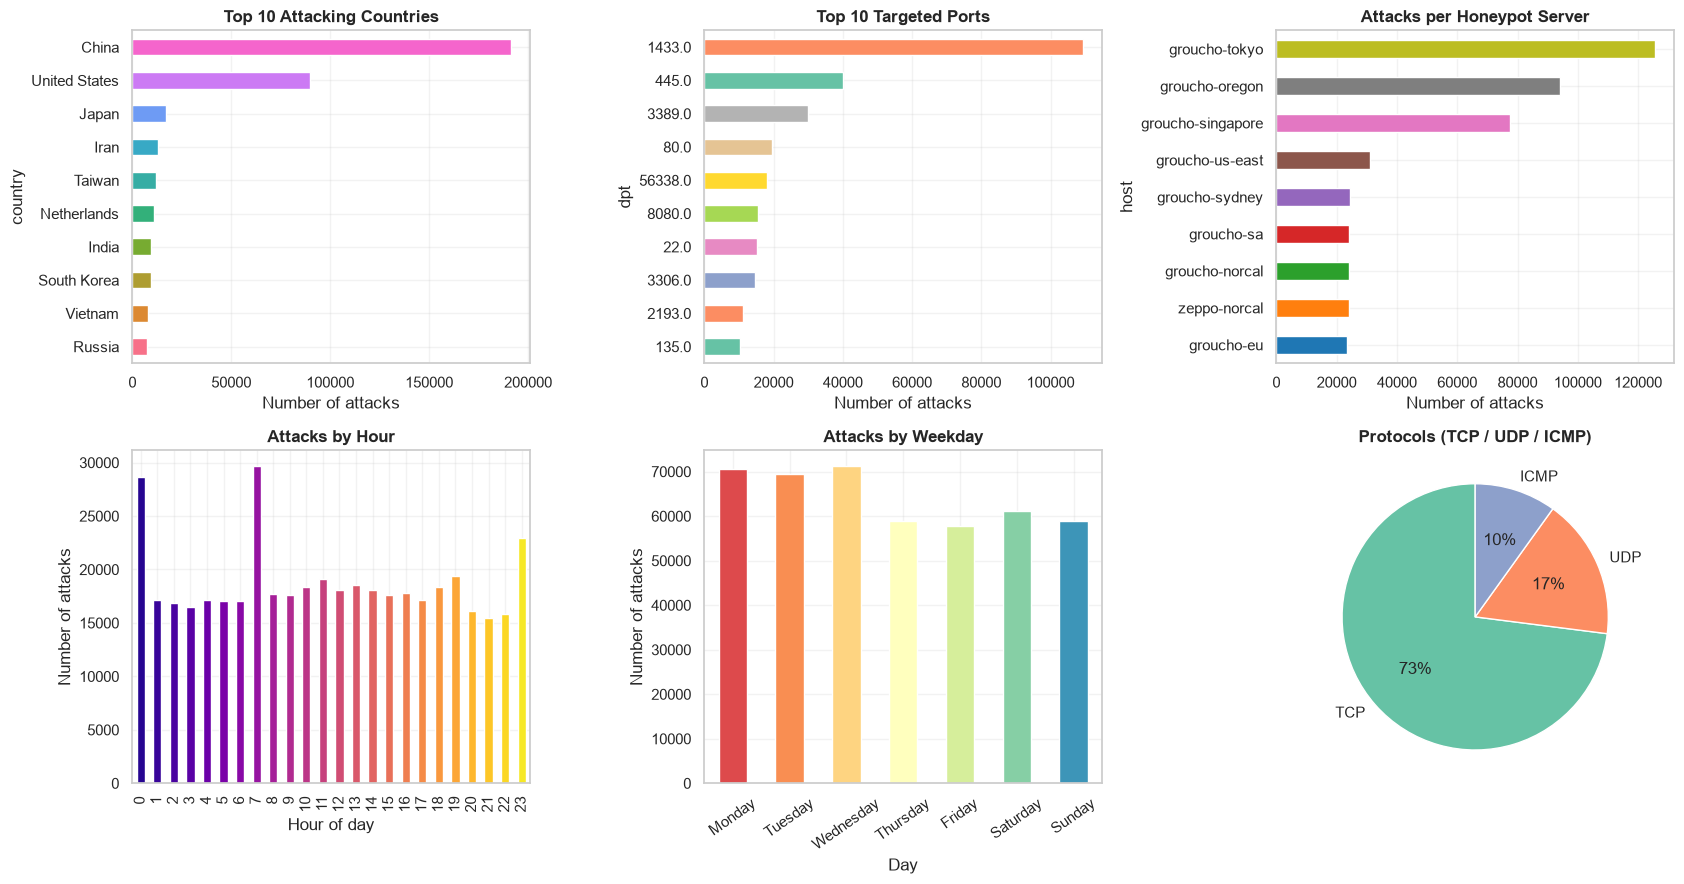

ICMP message types: {8.0: 38220, 3.0: 4240, 11.0: 1150, 0.0: 535, 13.0: 142, 5.0: 127, 12.0: 2}


In [5]:
# STEP 2 - EXPLORE THE DATA


print("\n" + "=" * 70)
print("STEP 2 - EXPLORING THE DATA")
print("=" * 70)


# Create six colorful charts.
fig, axes = plt.subplots(
    2,
    3,
    figsize=(17, 9)
)


# Different colors make the dashboard easier to read.
bar_colors_1 = sns.color_palette("husl", 10)
bar_colors_2 = sns.color_palette("Set2", 10)
bar_colors_3 = sns.color_palette("tab10", 10)


# Chart 1 - Countries
country_counts = df["country"].value_counts().head(10).sort_values()
country_counts.plot(
    kind="barh",
    ax=axes[0, 0],
    color=bar_colors_1
)
axes[0, 0].set_title("Top 10 Attacking Countries", fontweight="bold")
axes[0, 0].set_xlabel("Number of attacks")


# Chart 2 - Destination ports
port_counts = df["dpt"].value_counts().head(10).sort_values()
port_counts.plot(
    kind="barh",
    ax=axes[0, 1],
    color=bar_colors_2
)
axes[0, 1].set_title("Top 10 Targeted Ports", fontweight="bold")
axes[0, 1].set_xlabel("Number of attacks")


# Chart 3 - Honeypot hosts
host_counts_chart = df["host"].value_counts().head(10).sort_values()
host_counts_chart.plot(
    kind="barh",
    ax=axes[0, 2],
    color=bar_colors_3
)
axes[0, 2].set_title("Attacks per Honeypot Server", fontweight="bold")
axes[0, 2].set_xlabel("Number of attacks")


# Chart 4 - Hour
hour_counts = df.groupby(df["datetime"].dt.hour).size()
hour_counts.plot(
    kind="bar",
    ax=axes[1, 0],
    color=sns.color_palette("plasma", len(hour_counts))
)
axes[1, 0].set_title("Attacks by Hour", fontweight="bold")
axes[1, 0].set_xlabel("Hour of day")
axes[1, 0].set_ylabel("Number of attacks")


# Chart 5 - Day of week
day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

day_counts = df.groupby(
    df["datetime"].dt.day_name()
).size().reindex(day_order)

day_counts.plot(
    kind="bar",
    ax=axes[1, 1],
    color=sns.color_palette("Spectral", 7)
)
axes[1, 1].set_title("Attacks by Weekday", fontweight="bold")
axes[1, 1].set_xlabel("Day")
axes[1, 1].set_ylabel("Number of attacks")
axes[1, 1].tick_params(axis="x", rotation=35)


# Chart 6 - Protocols
protocol_counts = df["proto"].value_counts()
protocol_counts.plot(
    kind="pie",
    ax=axes[1, 2],
    autopct="%1.0f%%",
    startangle=90,
    colors=sns.color_palette("Set2", len(protocol_counts))
)
axes[1, 2].set_ylabel("")
axes[1, 2].set_title("Protocols (TCP / UDP / ICMP)", fontweight="bold")


for ax in axes.flat:
    ax.grid(axis="both", alpha=0.25)


plt.tight_layout()
plt.show()


# ICMP information
icmp_counts = (
    df["type"]
    .value_counts()
    .dropna()
    .astype(int)
    .to_dict()
)

print(
    "ICMP message types:",
    icmp_counts
)

In [6]:
# STEP 3 - CREATE FEATURES FOR EACH ATTACKER IP

print("\n" + "=" * 70)
print("STEP 3 - CREATING FEATURES")
print("=" * 70)

print(
    "The goal is to create one row for each attacker IP."
)


# ------------------------------------------------
# Port groups
# ------------------------------------------------

PORT_GROUPS = {

    "db": [
        1433,
        3306,
        5432,
        1521,
        6379,
        27017
    ],

    "smb": [
        135,
        139,
        445
    ],

    "rdp": [
        3389,
        5900
    ],

    "remote": [
        22,
        23,
        2222
    ],

    "web": [
        80,
        81,
        443,
        8000,
        8080,
        8088,
        8090,
        8888
    ],

    "mail": [
        25,
        110,
        143
    ],

    "udp": [
        19,
        53,
        161,
        1900,
        5060
    ]
}


# Common service names.
SERVICES = {

    21: "FTP",
    22: "SSH",
    23: "Telnet",
    25: "SMTP",
    53: "DNS",
    80: "HTTP",
    110: "POP3",
    135: "RPC",
    139: "NetBIOS",
    443: "HTTPS",
    445: "SMB",
    1433: "MS-SQL",
    3306: "MySQL",
    3389: "RDP",
    5060: "SIP",
    5900: "VNC",
    8080: "HTTP-alt",
    8888: "HTTP-alt",
    1080: "SOCKS",
    3128: "Proxy",
    1723: "PPTP"
}


# Make another dataframe for feature creation.
d = df.copy()


# ------------------------------------------------
# Time features
# ------------------------------------------------

# Convert time into decimal hours.
hour = (
    d["datetime"].dt.hour
    +
    d["datetime"].dt.minute / 60
)


# Date only.
d["date"] = d["datetime"].dt.date


# Hour is circular:
# 23:00 and 00:00 are close to each other.
d["hour_sin"] = np.sin(
    2 * np.pi * hour / 24
)

d["hour_cos"] = np.cos(
    2 * np.pi * hour / 24
)


# Night = before 6 AM.
d["night"] = (
    d["datetime"].dt.hour < 6
)


# Weekend = Saturday or Sunday.
d["weekend"] = (
    d["datetime"].dt.dayofweek >= 5
)


# ------------------------------------------------
# Protocol features
# ------------------------------------------------

d["tcp"] = (
    d["proto"] == "TCP"
)

d["udp"] = (
    d["proto"] == "UDP"
)

d["icmp"] = (
    d["proto"] == "ICMP"
)


# ------------------------------------------------
# ICMP type features
# ------------------------------------------------

d["icmp_echo"] = (
    d["type"] == 8
)

d["icmp_unreach"] = (
    d["type"] == 3
)


# ------------------------------------------------
# Port features
# ------------------------------------------------

d["well_known"] = (
    d["dpt"] < 1024
)

d["high_port"] = (
    d["dpt"] >= 10000
)

d["spt6000"] = (
    d["spt"] == 6000
)


# Create one feature for every port group.
for group_name in PORT_GROUPS:

    ports = PORT_GROUPS[group_name]

    d["f_" + group_name] = (
        d["dpt"].isin(ports)
    )


# ------------------------------------------------
# Basic information for each IP
# ------------------------------------------------

# Number of events
events = d.groupby(
    "srcstr"
).size()


# Number of different destination ports
unique_destination_ports = d.groupby(
    "srcstr"
)["dpt"].nunique()


# Number of different source ports
unique_source_ports = d.groupby(
    "srcstr"
)["spt"].nunique()


# Number of different honeypot servers
unique_hosts = d.groupby(
    "srcstr"
)["host"].nunique()


# Number of active days
active_days = d.groupby(
    "srcstr"
)["date"].nunique()


# First attack time
first_attack = d.groupby(
    "srcstr"
)["datetime"].min()


# Last attack time
last_attack = d.groupby(
    "srcstr"
)["datetime"].max()


# First known latitude and longitude
first_latitude = d.groupby(
    "srcstr"
)["latitude"].first()

first_longitude = d.groupby(
    "srcstr"
)["longitude"].first()


# First known country
first_country = d.groupby(
    "srcstr"
)["country"].first()

first_cc = d.groupby(
    "srcstr"
)["cc"].first()

first_region = d.groupby(
    "srcstr"
)["locale"].first()

first_region_code = d.groupby(
    "srcstr"
)["localeabbr"].first()

first_postalcode = d.groupby(
    "srcstr"
)["postalcode"].first()


# ------------------------------------------------
# Protocol percentages
# ------------------------------------------------

percent_tcp = d.groupby(
    "srcstr"
)["tcp"].mean()

percent_udp = d.groupby(
    "srcstr"
)["udp"].mean()

percent_icmp = d.groupby(
    "srcstr"
)["icmp"].mean()


# ICMP percentages
percent_icmp_echo = d.groupby(
    "srcstr"
)["icmp_echo"].mean()

percent_icmp_unreach = d.groupby(
    "srcstr"
)["icmp_unreach"].mean()


# Port behaviour
percent_well_known = d.groupby(
    "srcstr"
)["well_known"].mean()

percent_high_port = d.groupby(
    "srcstr"
)["high_port"].mean()

percent_spt6000 = d.groupby(
    "srcstr"
)["spt6000"].mean()


# Repeated packet percentage
repeat_ratio = d.groupby(
    "srcstr"
)["is_repeat"].mean()


# Night activity percentage
night_ratio = d.groupby(
    "srcstr"
)["night"].mean()


# Weekend activity percentage
weekend_ratio = d.groupby(
    "srcstr"
)["weekend"].mean()


# Time behaviour
average_hour_sin = d.groupby(
    "srcstr"
)["hour_sin"].mean()

average_hour_cos = d.groupby(
    "srcstr"
)["hour_cos"].mean()


STEP 3 - CREATING FEATURES
The goal is to create one row for each attacker IP.


In [7]:
# Create the attacker profile table

prof = pd.DataFrame()

prof["events"] = events
prof["uniq_dpt"] = unique_destination_ports
prof["uniq_spt"] = unique_source_ports
prof["uniq_hosts"] = unique_hosts
prof["active_days"] = active_days
prof["first"] = first_attack
prof["last"] = last_attack
prof["lat"] = first_latitude
prof["lon"] = first_longitude
prof["country"] = first_country
prof["cc"] = first_cc
prof["region"] = first_region
prof["region_code"] = first_region_code
prof["postalcode"] = first_postalcode

prof["pct_tcp"] = percent_tcp
prof["pct_udp"] = percent_udp
prof["pct_icmp"] = percent_icmp

prof["icmp_echo"] = percent_icmp_echo
prof["icmp_unreach"] = percent_icmp_unreach

prof["well_known"] = percent_well_known
prof["f_highport"] = percent_high_port
prof["spt6000"] = percent_spt6000

prof["repeat_ratio"] = repeat_ratio
prof["night_ratio"] = night_ratio
prof["weekend_ratio"] = weekend_ratio

prof["hour_sin"] = average_hour_sin
prof["hour_cos"] = average_hour_cos


# ------------------------------------------------
# Add port-group percentages
# ------------------------------------------------

for group_name in PORT_GROUPS:

    column_name = "f_" + group_name

    prof[column_name] = d.groupby(
        "srcstr"
    )[column_name].mean()


# ------------------------------------------------
# Time span
# ------------------------------------------------

span_hours = (
    prof["last"] - prof["first"]
).dt.total_seconds() / 3600


# Maximum number of packets at one exact timestamp.
burst = (
    d.groupby(
        ["srcstr", "datetime"]
    )
    .size()
    .groupby("srcstr")
    .max()
)


# ------------------------------------------------
# Port entropy
# ------------------------------------------------

# Count how many times each IP contacted each destination port.
port_counts = (
    d.dropna(subset=["dpt"])
    .groupby(["srcstr", "dpt"])
    .size()
    .rename("n")
    .reset_index()
)


# Probability of each destination port for each IP.
port_counts["p"] = (
    port_counts["n"]
    /
    port_counts.groupby("srcstr")["n"]
    .transform("sum")
)


# Entropy part.
port_counts["h"] = (
    -port_counts["p"]
    *
    np.log2(port_counts["p"])
)


port_entropy = (
    port_counts.groupby("srcstr")["h"]
    .sum()
)


prof["port_entropy"] = port_entropy
prof["port_entropy"] = prof["port_entropy"].fillna(0)


# ------------------------------------------------
# Most targeted port
# ------------------------------------------------

most_used_port = (
    port_counts
    .sort_values("n")
    .drop_duplicates(
        "srcstr",
        keep="last"
    )
    .set_index("srcstr")["dpt"]
)


prof["top_port"] = most_used_port


# Convert port number into service name.
def get_service_name(port):

    if pd.isna(port):
        return "ICMP/none"

    return SERVICES.get(
        int(port),
        "port " + str(int(port))
    )


prof["top_service"] = (
    prof["top_port"]
    .map(get_service_name)
)


# ------------------------------------------------
# Most targeted honeypot
# ------------------------------------------------

host_counts = (
    d.groupby(
        ["srcstr", "host"]
    )
    .size()
    .rename("n")
    .reset_index()
)


most_used_host = (
    host_counts
    .sort_values("n")
    .drop_duplicates(
        "srcstr",
        keep="last"
    )
    .set_index("srcstr")["host"]
)


prof["top_host"] = most_used_host


# ------------------------------------------------
# Log transformed features
# ------------------------------------------------

prof["log_events"] = np.log1p(
    prof["events"]
)

prof["log_uniq_dpt"] = np.log1p(
    prof["uniq_dpt"]
)

prof["log_uniq_spt"] = np.log1p(
    prof["uniq_spt"]
)

prof["log_span_h"] = np.log1p(
    span_hours
)

prof["log_active_days"] = np.log1p(
    prof["active_days"]
)

prof["log_burst"] = np.log1p(
    burst
)

prof["log_rate"] = np.log1p(
    prof["events"]
    /
    (span_hours + 1)
)


# Replace IP index with a normal column.
prof = prof.reset_index()

prof = prof.rename(
    columns={"srcstr": "ip"}
)


prof["region"] = (
    prof["region"].fillna("unknown")
)


# How many attacker IPs come from the same country code?
country_ip_count = (
    prof.groupby("cc")["ip"]
    .transform("size")
)

prof["log_country_pop"] = np.log1p(
    country_ip_count
)


# ------------------------------------------------
# IP octets
# ------------------------------------------------

ip_octets = (
    prof["ip"]
    .str.split(
        ".",
        expand=True
    )
    .astype(int)
)

prof["oct1"] = ip_octets[0]
prof["oct2"] = ip_octets[1]

In [8]:
# Final feature list


FEATURES = [

    "log_events",
    "log_uniq_dpt",
    "log_uniq_spt",
    "uniq_hosts",
    "log_rate",
    "log_span_h",
    "log_active_days",
    "log_burst",
    "port_entropy",

    "pct_tcp",
    "pct_udp",
    "pct_icmp",

    "icmp_echo",
    "icmp_unreach",

    "well_known",
    "f_highport",
    "spt6000",

    "repeat_ratio",
    "night_ratio",
    "weekend_ratio",

    "hour_sin",
    "hour_cos",

    "f_db",
    "f_smb",
    "f_rdp",
    "f_remote",
    "f_web",
    "f_mail",
    "f_udp",

    "log_country_pop",

    "lat",
    "lon",

    "oct1",
    "oct2"
]


# Fill missing feature values.
for feature in FEATURES:

    prof[feature] = pd.to_numeric(
        prof[feature],
        errors="coerce"
    )

    prof[feature] = prof[feature].fillna(
        prof[feature].median()
    )


# ------------------------------------------------
# Standardization
# ------------------------------------------------

scaler = StandardScaler()

X = scaler.fit_transform(
    prof[FEATURES]
)


print(
    "Number of attacker IPs:",
    len(prof)
)

print(
    "Number of features per IP:",
    len(FEATURES)
)

print("\nExample attacker profiles:")

display(
    prof[
        [
            "ip",
            "country",
            "region",
            "events",
            "uniq_dpt",
            "uniq_hosts",
            "top_service",
            "top_host"
        ]
    ].head()
)

Number of attacker IPs: 69113
Number of features per IP: 34

Example attacker profiles:


,ip,country,region,events,uniq_dpt,uniq_hosts,top_service,top_host
0,1.0.0.38,Australia,unknown,2,1,1,SMB,groucho-tokyo
1,1.1.162.110,Thailand,unknown,1,1,1,port 3544,groucho-norcal
2,1.112.102.204,Japan,unknown,2,1,1,SMB,groucho-tokyo
3,1.112.62.198,Japan,unknown,4,1,1,SMB,zeppo-norcal
4,1.113.49.108,Japan,unknown,3,1,2,SMB,zeppo-norcal


In [9]:
# STEP 4 - CHOOSE NUMBER OF CLUSTERS

print("\n" + "=" * 70)
print("STEP 4 - CHOOSING NUMBER OF CLUSTERS")
print("=" * 70)

if FAST_MODE:
    cluster_numbers = range(3, 9)
else:
    cluster_numbers = range(3, 12)


# Silhouette score can be slow.
# Use at most 10,000 records for this score.
random_generator = np.random.RandomState(
    RANDOM_STATE
)

sample_size = min(
    10000,
    len(X)
)

sample_indices = random_generator.choice(
    len(X),
    sample_size,
    replace=False
)


kmeans_results = []
gmm_results = []


for number in cluster_numbers:

    print(
        "Testing cluster number:",
        number
    )


    # -------------------------------
    # K-Means
    # -------------------------------

    test_kmeans = KMeans(
        n_clusters=number,
        n_init=5,
        random_state=RANDOM_STATE
    )

    kmeans_labels = test_kmeans.fit_predict(
        X
    )


    kmeans_ch = calinski_harabasz_score(
        X,
        kmeans_labels
    )

    kmeans_db = davies_bouldin_score(
        X,
        kmeans_labels
    )

    kmeans_silhouette = silhouette_score(
        X[sample_indices],
        kmeans_labels[sample_indices]
    )


    kmeans_results.append({

        "k": number,

        "CH": kmeans_ch,

        "DB": kmeans_db,

        "Silhouette": kmeans_silhouette
    })


    # -------------------------------
    # GMM
    # -------------------------------

    test_gmm = GaussianMixture(
        n_components=number,
        covariance_type="full",
        reg_covar=0.0001,
        random_state=RANDOM_STATE
    )

    test_gmm.fit(X)

    gmm_labels = test_gmm.predict(X)


    gmm_ch = calinski_harabasz_score(
        X,
        gmm_labels
    )

    gmm_db = davies_bouldin_score(
        X,
        gmm_labels
    )

    gmm_bic = test_gmm.bic(X)


    gmm_results.append({

        "k": number,

        "CH": gmm_ch,

        "DB": gmm_db,

        "BIC": gmm_bic
    })


# Convert results into dataframes.
kmeans_results = pd.DataFrame(
    kmeans_results
).set_index("k")


gmm_results = pd.DataFrame(
    gmm_results
).set_index("k")


STEP 4 - CHOOSING NUMBER OF CLUSTERS
Testing cluster number: 3
Testing cluster number: 4
Testing cluster number: 5
Testing cluster number: 6
Testing cluster number: 7
Testing cluster number: 8


Text(0.5, 1.0, 'K-Means Silhouette (higher is better)')

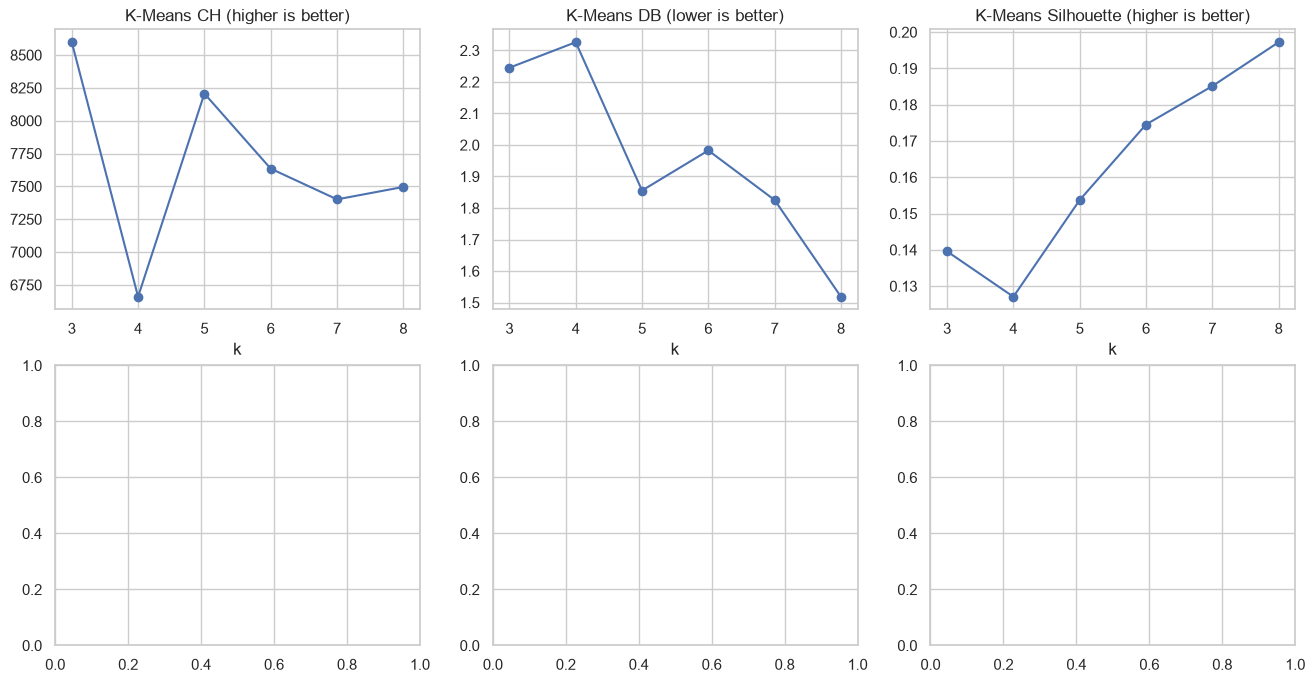

In [10]:
# Plot K-Means results


fig, axes = plt.subplots(
    2,
    3,
    figsize=(16, 8)
)


kmeans_results["CH"].plot(
    marker="o",
    ax=axes[0, 0]
)

axes[0, 0].set_title(
    "K-Means CH (higher is better)"
)


kmeans_results["DB"].plot(
    marker="o",
    ax=axes[0, 1]
)

axes[0, 1].set_title(
    "K-Means DB (lower is better)"
)


kmeans_results["Silhouette"].plot(
    marker="o",
    ax=axes[0, 2]
)

axes[0, 2].set_title(
    "K-Means Silhouette (higher is better)"
)

In [11]:
# Plot GMM results


gmm_results["CH"].plot(
    marker="o",
    ax=axes[1, 0]
)

axes[1, 0].set_title(
    "GMM CH (higher is better)"
)


gmm_results["DB"].plot(
    marker="o",
    ax=axes[1, 1]
)

axes[1, 1].set_title(
    "GMM DB (lower is better)"
)


gmm_results["BIC"].plot(
    marker="o",
    ax=axes[1, 2]
)

axes[1, 2].set_title(
    "GMM BIC (lower is better)"
)


plt.tight_layout()
plt.show()


# Choose K-Means using best silhouette.
best_kmeans_clusters = int(
    kmeans_results["Silhouette"].idxmax()
)


# Choose GMM using lowest BIC.
best_gmm_components = int(
    gmm_results["BIC"].idxmin()
)


print(
    "\nChosen K-Means clusters:",
    best_kmeans_clusters
)

print(
    "Chosen GMM components:",
    best_gmm_components
)

<Figure size 640x480 with 0 Axes>


Chosen K-Means clusters: 8
Chosen GMM components: 8


In [12]:

# TRAIN FINAL MODELS AND CREATE RISK SCORE


print("\n" + "=" * 70)
print("STEP 5 - TRAINING FINAL MODELS")
print("=" * 70)


# ------------------------------------------------
# Model 1: K-Means
# ------------------------------------------------

kmeans_model = KMeans(
    n_clusters=best_kmeans_clusters,
    n_init=10,
    random_state=RANDOM_STATE
)

kmeans_model.fit(X)


# ------------------------------------------------
# Model 2: GMM
# ------------------------------------------------

gmm_model = GaussianMixture(
    n_components=best_gmm_components,
    covariance_type="full",
    reg_covar=0.0001,
    random_state=RANDOM_STATE
)

gmm_model.fit(X)


# ------------------------------------------------
# Model 3: Isolation Forest
# ------------------------------------------------

isolation_model = IsolationForest(
    n_estimators=300,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

isolation_model.fit(X)


print("All three models trained.")


# ------------------------------------------------
# K-Means anomaly score
# ------------------------------------------------

# Distance from every IP to every cluster centre.
all_kmeans_distances = kmeans_model.transform(X)

# Take the nearest cluster distance.
kmeans_score = all_kmeans_distances.min(
    axis=1
)


# ------------------------------------------------
# GMM anomaly score
# ------------------------------------------------

# Higher negative log likelihood = more unusual.
gmm_score = -gmm_model.score_samples(X)


# ------------------------------------------------
# Isolation Forest anomaly score
# ------------------------------------------------

# Higher value after changing sign = more unusual.
isolation_score = -isolation_model.score_samples(X)


# ------------------------------------------------
# Convert scores to percentiles
# ------------------------------------------------

def get_percentile_scores(values):

    sorted_values = np.sort(values)

    result = []

    for value in values:

        position = np.searchsorted(
            sorted_values,
            value
        )

        result.append(
            position / len(sorted_values)
        )

    return np.array(result)


kmeans_percentile = get_percentile_scores(
    kmeans_score
)

gmm_percentile = get_percentile_scores(
    gmm_score
)

isolation_percentile = get_percentile_scores(
    isolation_score
)


# ------------------------------------------------
# Ensemble risk
# ------------------------------------------------

# Average the three model scores.
ensemble_score = (
    kmeans_percentile
    +
    gmm_percentile
    +
    isolation_percentile
) / 3


# Convert ensemble score into final risk.
final_risk = get_percentile_scores(
    ensemble_score
)


prof["risk"] = final_risk
# Preserve the raw ensemble score before applying any external threat intelligence.
prof["model_risk"] = prof["risk"].astype(float)
prof["threat_intel_match"] = False
prof["risk_source"] = "ML ensemble anomaly score"


# Cluster labels
prof["kmeans_cluster"] = (
    kmeans_model.labels_
)

prof["gmm_cluster"] = (
    gmm_model.predict(X)
)


# ------------------------------------------------
# Anomaly flags
# ------------------------------------------------

kmeans_threshold = np.quantile(
    kmeans_score,
    0.95
)

gmm_threshold = np.quantile(
    gmm_score,
    0.95
)

isolation_threshold = np.quantile(
    isolation_score,
    0.95
)


prof["kmeans_anomaly"] = (
    kmeans_score > kmeans_threshold
)

prof["gmm_anomaly"] = (
    gmm_score > gmm_threshold
)

prof["if_anomaly"] = (
    isolation_score > isolation_threshold
)


# ------------------------------------------------
# Severity
# ------------------------------------------------

def get_severity(risk):

    if risk >= 0.97:
        return "critical"

    elif risk >= 0.90:
        return "high"

    elif risk >= 0.75:
        return "medium"

    else:
        return "low"


prof["severity"] = (
    prof["risk"].apply(get_severity)
)


print("\nSeverity counts:")

print(
    prof["severity"].value_counts()
)


STEP 5 - TRAINING FINAL MODELS
All three models trained.

Severity counts:
severity
low         51835
medium      10367
high         4838
critical     2073
Name: count, dtype: int64



STEP 6 - MODEL COMPARISON AND PCA

Model comparison:


,Model,Clusters,Calinski-Harabasz,Davies-Bouldin,Silhouette
0,K-Means,8,7572.254,1.778,0.200
1,GMM,8,6324.994,1.908,0.186



K-Means anomalies: 3456
GMM anomalies: 3456
Isolation Forest anomalies: 3456
K-Means + GMM agree on: 1048 IPs
All three models agree on: 786 IPs

The two PCA components keep 25.27 % of the information.


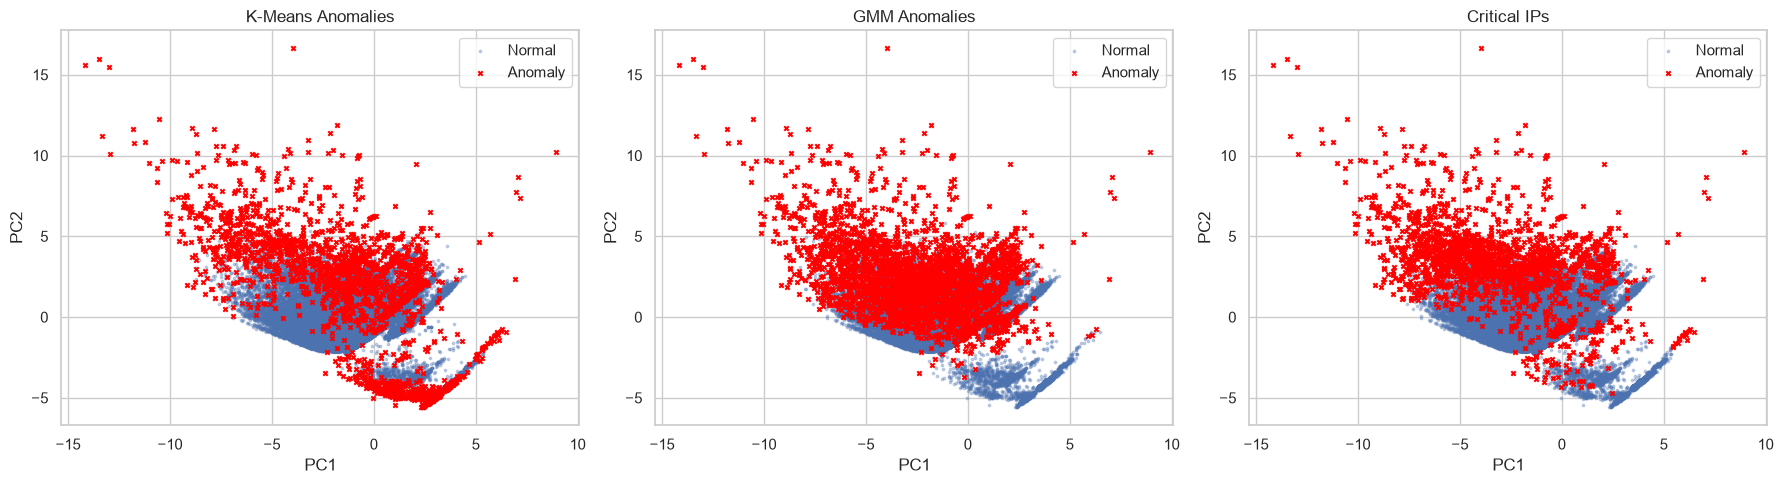


Average behaviour of K-Means clusters:


,ips,avg_events,avg_ports,avg_servers,common_service,top_country
kmeans_cluster,,,,,,
0,18360,2.4,1.0,1.0,SMB,United States
1,15013,2.9,1.1,1.3,MS-SQL,China
2,4826,3.3,0.0,1.5,ICMP/none,China
3,3305,16.4,1.2,1.0,port 20029,Japan
4,11162,2.4,1.3,1.4,RDP,China
5,7751,1.8,1.0,1.4,Telnet,China
6,1863,9.5,1.1,3.4,SIP,United States
7,6833,34.1,2.6,4.4,MS-SQL,China


In [13]:

# MODEL COMPARISON AND PCA

print("\n" + "=" * 70)
print("STEP 6 - MODEL COMPARISON AND PCA")
print("=" * 70)


# Labels
kmeans_labels = kmeans_model.labels_

gmm_labels = prof[
    "gmm_cluster"
].values


# Evaluation scores
kmeans_ch = calinski_harabasz_score(
    X,
    kmeans_labels
)

kmeans_db = davies_bouldin_score(
    X,
    kmeans_labels
)

kmeans_silhouette = silhouette_score(
    X[sample_indices],
    kmeans_labels[sample_indices]
)


gmm_ch = calinski_harabasz_score(
    X,
    gmm_labels
)

gmm_db = davies_bouldin_score(
    X,
    gmm_labels
)

gmm_silhouette = silhouette_score(
    X[sample_indices],
    gmm_labels[sample_indices]
)


comparison = pd.DataFrame({

    "Model": [
        "K-Means",
        "GMM"
    ],

    "Clusters": [
        best_kmeans_clusters,
        best_gmm_components
    ],

    "Calinski-Harabasz": [
        kmeans_ch,
        gmm_ch
    ],

    "Davies-Bouldin": [
        kmeans_db,
        gmm_db
    ],

    "Silhouette": [
        kmeans_silhouette,
        gmm_silhouette
    ]
})


print("\nModel comparison:")

display(
    comparison.round(3)
)


# Count anomalies
kmeans_anomalies = (
    prof["kmeans_anomaly"]
)

gmm_anomalies = (
    prof["gmm_anomaly"]
)

if_anomalies = (
    prof["if_anomaly"]
)


print(
    "\nK-Means anomalies:",
    kmeans_anomalies.sum()
)

print(
    "GMM anomalies:",
    gmm_anomalies.sum()
)

print(
    "Isolation Forest anomalies:",
    if_anomalies.sum()
)

print(
    "K-Means + GMM agree on:",
    (
        kmeans_anomalies
        &
        gmm_anomalies
    ).sum(),
    "IPs"
)

print(
    "All three models agree on:",
    (
        kmeans_anomalies
        &
        gmm_anomalies
        &
        if_anomalies
    ).sum(),
    "IPs"
)


# ------------------------------------------------
# PCA
# ------------------------------------------------

pca = PCA(
    n_components=2
)

pca_data = pca.fit_transform(
    X
)


explained_information = (
    pca.explained_variance_ratio_.sum()
    * 100
)


print(
    "\nThe two PCA components keep",
    round(explained_information, 2),
    "% of the information."
)


# Three PCA plots.
fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 5)
)


flags = [
    prof["kmeans_anomaly"],
    prof["gmm_anomaly"],
    prof["risk"] >= 0.97
]


titles = [
    "K-Means Anomalies",
    "GMM Anomalies",
    "Critical IPs"
]


for i in range(3):

    normal = ~flags[i]
    anomaly = flags[i]


    axes[i].scatter(
        pca_data[normal, 0],
        pca_data[normal, 1],
        s=3,
        alpha=0.3,
        label="Normal"
    )


    axes[i].scatter(
        pca_data[anomaly, 0],
        pca_data[anomaly, 1],
        s=10,
        c="red",
        marker="x",
        label="Anomaly"
    )


    axes[i].set_title(
        titles[i]
    )

    axes[i].set_xlabel(
        "PC1"
    )

    axes[i].set_ylabel(
        "PC2"
    )

    axes[i].legend()


plt.tight_layout()
plt.show()


# ------------------------------------------------
# Understand K-Means clusters
# ------------------------------------------------

print(
    "\nAverage behaviour of K-Means clusters:"
)


cluster_summary = (
    prof.groupby("kmeans_cluster")
    .agg(
        ips=("ip", "size"),
        avg_events=("events", "mean"),
        avg_ports=("uniq_dpt", "mean"),
        avg_servers=("uniq_hosts", "mean"),

        common_service=(
            "top_service",
            lambda values: values.mode().iat[0]
        ),

        top_country=(
            "country",
            lambda values: values.mode().iat[0]
        )
    )
)


display(
    cluster_summary.round(1)
)


STEP 7 - MOST SUSPICIOUS IPs


,ip,country,risk,severity,events,uniq_dpt,uniq_hosts,top_service
66980,93.174.88.32,Netherlands,1.0,critical,533,189,9,port 8085
1965,107.6.118.131,Singapore,1.0,critical,42,42,1,port 33518
28623,183.91.14.60,Vietnam,1.0,critical,5676,629,7,Proxy
45980,222.73.45.233,China,1.0,critical,105,105,4,port 4404
65737,89.248.171.125,Netherlands,1.0,critical,672,3,9,DNS
65739,89.248.171.71,Netherlands,1.0,critical,401,2,9,DNS
17907,123.151.42.61,China,1.0,critical,2663,46,9,HTTP-alt
58861,66.197.180.74,United States,1.0,critical,145,142,6,port 63106
59248,68.145.164.27,Canada,1.0,critical,2834,1,1,HTTP
13941,119.63.199.69,Japan,1.0,critical,882,0,9,ICMP/none



Average behaviour of each severity level:


,events,uniq_dpt,uniq_hosts,port_entropy,repeat_ratio,night_ratio,f_db,f_smb,f_rdp,f_remote,f_web
severity,,,,,,,,,,,
critical,88.283,4.648,4.835,1.095,0.203,0.289,0.100,0.064,0.053,0.045,0.315
high,13.836,1.791,3.447,0.581,0.130,0.265,0.176,0.156,0.065,0.049,0.239
medium,6.308,1.059,2.279,0.201,0.160,0.275,0.185,0.110,0.077,0.034,0.075
low,2.560,0.986,1.201,0.028,0.205,0.208,0.275,0.308,0.132,0.145,0.011


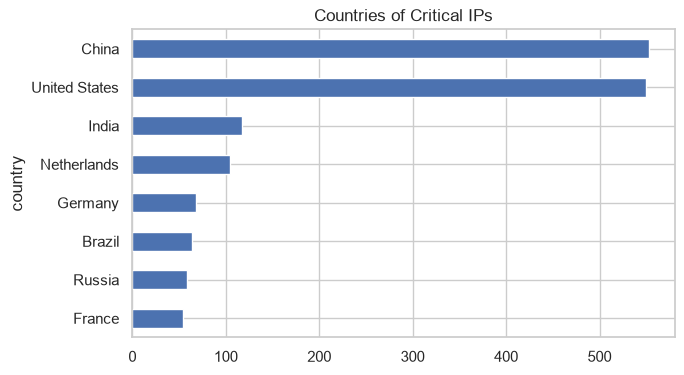

In [14]:
# MOST SUSPICIOUS IPs


print("\n" + "=" * 70)
print("STEP 7 - MOST SUSPICIOUS IPs")
print("=" * 70)


top_ips = (
    prof
    .sort_values(
        "risk",
        ascending=False
    )
    .head(15)
)


display(
    top_ips[
        [
            "ip",
            "country",
            "risk",
            "severity",
            "events",
            "uniq_dpt",
            "uniq_hosts",
            "top_service"
        ]
    ].round(3)
)


# Average behaviour by severity.
severity_features = [

    "events",
    "uniq_dpt",
    "uniq_hosts",
    "port_entropy",
    "repeat_ratio",
    "night_ratio",
    "f_db",
    "f_smb",
    "f_rdp",
    "f_remote",
    "f_web"
]


print(
    "\nAverage behaviour of each severity level:"
)


severity_summary = (
    prof.groupby("severity")
    [severity_features]
    .mean()
)


severity_order = [
    "critical",
    "high",
    "medium",
    "low"
]


severity_order = [
    x for x in severity_order
    if x in severity_summary.index
]


display(
    severity_summary
    .loc[severity_order]
    .round(3)
)


# Countries of critical IPs.
critical_country_counts = (
    prof[
        prof["risk"] >= 0.97
    ]["country"]
    .value_counts()
    .head(8)
)


critical_country_counts.plot(
    kind="barh",
    figsize=(7, 4),
    title="Countries of Critical IPs"
)

plt.gca().invert_yaxis()

plt.show()

In [15]:
#  INTERACTIVE MAP DASHBOARD


print("\n" + "=" * 70)
print("STEP 8 - BUILDING INTERACTIVE MAP DASHBOARD")
print("=" * 70)

print(
    "This section creates the browser map."
)

print(
    "The HTML code is long because it creates the map controls."
)


STEP 8 - BUILDING INTERACTIVE MAP DASHBOARD
This section creates the browser map.
The HTML code is long because it creates the map controls.


In [16]:
# JavaScript/Leaflet map template.

MAP_TEMPLATE = r"""
<!doctype html>

<html>

<head>

<meta charset="utf-8">

<title>__TITLE__</title>

<link
rel="stylesheet"
href="https://cdnjs.cloudflare.com/ajax/libs/leaflet/1.9.4/leaflet.min.css"
>

<link
rel="stylesheet"
href="https://unpkg.com/leaflet.markercluster@1.5.3/dist/MarkerCluster.css"
>

<link
rel="stylesheet"
href="https://unpkg.com/leaflet.markercluster@1.5.3/dist/MarkerCluster.Default.css"
>

<style>

html, body {
    height: 100%;
    margin: 0;
    font-family: Arial, sans-serif;
}

#map {
    height: 100%;
}

#panel {
    position: absolute;
    top: 10px;
    right: 10px;
    z-index: 1000;
    background: white;
    padding: 10px 12px;
    border-radius: 8px;
    width: 235px;
    box-shadow: 0 1px 8px #0007;
    font-size: 13px;
    display: __PANEL__;
    max-height: 90vh;
    overflow: auto;
}

#panel input,
#panel select {
    width: 100%;
    margin: 3px 0 8px;
    box-sizing: border-box;
}

#panel input[type=checkbox] {
    width: auto;
}

h3 {
    margin: 0 0 8px;
}

</style>

</head>


<body>

<div id="map"></div>


<div id="panel">

<h3>__TITLE__</h3>

<div style="margin-bottom:8px;">
<a href="/threat_map.html" target="_blank" style="text-decoration:none; font-weight:bold;">Open full-screen map ↗</a>
</div>

Search IP (press Enter or click Search):

<div style="display:flex; gap:5px; margin-bottom:8px;">

<input
id="q"
type="text"
placeholder="e.g. 60.173.14.88"
style="flex:1; margin:0;"
>

<button
id="searchBtn"
type="button"
style="padding:5px 8px; cursor:pointer;"
>
Search
</button>

</div>

Minimum risk:

<b id="rv">0.90</b>

<input
id="risk"
type="range"
min="0"
max="0.995"
step="0.005"
value="0.90"
>


Country:

<select id="country">

<option value="">
All
</option>

</select>


<label>
<input
type="checkbox"
class="sev"
value="critical"
checked
>
Critical
</label>


<label>
<input
type="checkbox"
class="sev"
value="high"
checked
>
High
</label>


<label>
<input
type="checkbox"
class="sev"
value="medium"
checked
>
Medium
</label>


<label>
<input
type="checkbox"
class="sev"
value="low"
checked
>
Low
</label>


<div id="count"></div>

<div id="result"></div>

</div>


<script src="https://cdnjs.cloudflare.com/ajax/libs/leaflet/1.9.4/leaflet.min.js">
</script>

<script src="https://unpkg.com/leaflet.markercluster@1.5.3/dist/leaflet.markercluster.js">
</script>


<script>

const DATA = __DATA__;

const COLORS = {
    critical: '#e11d48',
    high: '#f97316',
    medium: '#eab308',
    low: '#22c55e'
};


function getElement(id) {
    return document.getElementById(id);
}


const map = L.map(
    'map',
    {worldCopyJump: false, maxBounds: [[-85, -180], [85, 180]], maxBoundsViscosity: 1.0, minZoom: 2}
).setView(
    [20, 0],
    2
);


const street = L.tileLayer(
    'https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}',
    {
        attribution: 'Tiles &copy; Esri',
        maxZoom: 18,
        noWrap: true
    }
).addTo(map);


const lightGray = L.tileLayer(
    'https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}',
    {
        attribution: 'Tiles &copy; Esri',
        maxZoom: 16,
        noWrap: true
    }
);


const satellite = L.tileLayer(
    'https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}',
    {
        attribution: 'Tiles &copy; Esri',
        maxZoom: 18,
        noWrap: true
    }
);


const openStreetMap = L.tileLayer(
    'https://tile.openstreetmap.org/{z}/{x}/{y}.png',
    {
        attribution: '&copy; OpenStreetMap contributors',
        maxZoom: 19,
        noWrap: true
    }
);

// Transparent reference layer for country/state/place names.
// This is especially useful on the satellite view, where labels are not built into the imagery.
const placeLabels = L.tileLayer(
    'https://server.arcgisonline.com/ArcGIS/rest/services/Reference/World_Reference_Overlay/MapServer/tile/{z}/{y}/{x}',
    {
        attribution: 'Labels &copy; Esri',
        maxZoom: 18,
        noWrap: true,
        opacity: 0.95
    }
).addTo(map);


L.control.layers(
    {
        'Street (Esri)': street,
        'Light gray (Esri)': lightGray,
        'Satellite (Esri)': satellite,
        'OpenStreetMap': openStreetMap
    },
    {
        'State / Place Names': placeLabels
    },
    null,
    {
        position: 'bottomleft'
    }
).addTo(map);


// Marker clustering prevents hundreds of nearby IPs from appearing as repeated/overlapping markers.
const markers = L.markerClusterGroup({
    showCoverageOnHover: false,
    spiderfyOnMaxZoom: true,
    removeOutsideVisibleBounds: true,
    maxClusterRadius: 45
});

map.addLayer(markers);


const countries = [];


for (let i = 0; i < DATA.length; i++) {

    if (!countries.includes(DATA[i].country)) {
        countries.push(DATA[i].country);
    }

}


countries.sort();


for (let i = 0; i < countries.length; i++) {

    const option = document.createElement('option');

    option.value = countries[i];

    option.textContent = countries[i];

    getElement('country').appendChild(option);

}


function makePopup(point) {

    const locationText = [
        point.locality,
        point.region_name,
        point.region_code,
        point.country,
        point.postalcode
    ].filter(Boolean).join(', ');

    const providerText = [
        point.isp,
        point.org
    ].filter(Boolean).join(' | ');

    return `
        <div style="min-width:260px; line-height:1.5;">
        <b style="font-size:16px;">${point.ip}</b>
        <hr style="margin:5px 0;">
        <b>Location:</b> ${locationText || 'Unknown'}<br>
        <b>Coordinates:</b> ${Number(point.lat).toFixed(4)}, ${Number(point.lon).toFixed(4)}<br>
        <b>Risk:</b> ${point.risk} (${point.severity})<br>
        <b>Events:</b> ${point.events}<br>
        <b>Unique ports:</b> ${point.ports}<br>
        <b>Main target:</b> ${point.service || 'unknown'}<br>
        ${providerText ? '<b>ISP / Organization:</b> ' + providerText + '<br>' : ''}
        ${point.timezone ? '<b>Timezone:</b> ' + point.timezone + '<br>' : ''}
        ${point.seen !== undefined ? '<b>Honeypot status:</b> ' + (point.seen ? 'Seen' : 'Not seen - estimate') : ''}
        </div>
    `;

}


async function searchIP() {

    const input = getElement('q');
    const ip = input.value.trim();

    if (!ip) {
        getElement('result').textContent = 'Please enter an IP address.';
        return;
    }

    // First check the IPs already stored in the dashboard.
    let point = null;

    for (let i = 0; i < DATA.length; i++) {
        if (DATA[i].ip === ip) {
            point = DATA[i];
            break;
        }
    }

    // If the IP is not in the dashboard, ask Python through the local server.
    if (!point) {

        getElement('result').textContent = 'Analysing ' + ip + ' ...';

        try {

            const response = await fetch(
                '/api/analyze?ip=' + encodeURIComponent(ip)
            );

            const result = await response.json();

            if (result.error) {
                getElement('result').textContent = result.error;
                return;
            }

            point = {
                ip: result.ip,
                lat: result.lat,
                lon: result.lon,
                country: result.country || 'Unknown',
                locality: result.locality || '',
                region_name: result.region_name || '',
                region_code: result.region_code || '',
                postalcode: result.postalcode || '',
                isp: result.isp || '',
                org: result.org || '',
                timezone: result.timezone || '',
                seen: result.seen,
                risk: Number(result.risk || 0),
                severity: result.severity || 'low',
                events: result.events || 0,
                ports: result.ports || 0,
                service: result.service || 'Unknown'
            };

        } catch (error) {

            getElement('result').innerHTML =
                '<b>New-IP search needs the notebook server.</b><br>' +
                'Open the Dashboard address printed by the notebook, ' +
                'such as http://127.0.0.1:8765/, and keep Jupyter running.';
            return;
        }
    }

    // Show the result.
    getElement('result').innerHTML =
        '<b>' + point.severity.toUpperCase() + '</b>' +
        ' &nbsp; Risk: <b>' + Number(point.risk).toFixed(3) + '</b><br>' +
        'IP: ' + point.ip + '<br>' +
        'Location: ' + [point.locality, point.region_name, point.region_code, point.country, point.postalcode].filter(Boolean).join(', ') + '<br>' +
        'Coordinates: ' + Number(point.lat).toFixed(4) + ', ' + Number(point.lon).toFixed(4) + '<br>' +
        'Events: ' + point.events + '<br>' +
        'Ports: ' + point.ports + '<br>' +
        'Main target: ' + point.service + '<br>' +
        (point.isp ? 'ISP: ' + point.isp + '<br>' : '') +
        (point.org ? 'Organization: ' + point.org : '');

    // Move the map to the searched IP if coordinates are available.
    if (point.lat !== null && point.lon !== null &&
        point.lat !== undefined && point.lon !== undefined) {

        L.marker([point.lat, point.lon])
            .addTo(map)
            .bindPopup(makePopup(point))
            .openPopup();

        map.flyTo([point.lat, point.lon], 5);
    }
}


// Enter key support.
getElement('q').addEventListener(
    'keydown',
    function(event) {
        if (event.key === 'Enter') {
            event.preventDefault();
            searchIP();
        }
    }
);


// Search button support.
getElement('searchBtn').addEventListener(
    'click',
    searchIP
);


function drawMarkers() {

    markers.clearLayers();


    const minimumRisk =
        Number(getElement('risk').value);


    const selectedCountry =
        getElement('country').value;


    const selectedSeverity = {};


    const checkboxes =
        document.querySelectorAll('.sev');


    for (let i = 0; i < checkboxes.length; i++) {

        selectedSeverity[
            checkboxes[i].value
        ] = checkboxes[i].checked;

    }


    let shown = 0;


    for (let i = 0; i < DATA.length; i++) {

        const point = DATA[i];


        if (point.risk < minimumRisk) {
            continue;
        }


        if (
            selectedCountry &&
            point.country !== selectedCountry
        ) {
            continue;
        }


        if (
            !selectedSeverity[
                point.severity
            ]
        ) {
            continue;
        }


        shown++;


        L.circleMarker(
            [point.lat, point.lon],
            {
                radius: 4 + point.risk * 5,
                color: COLORS[point.severity],
                fillColor: COLORS[point.severity],
                fillOpacity: 0.6,
                weight: 1
            }
        )
        .bindPopup(
            makePopup(point)
        )
        .addTo(markers);

    }


    getElement('count').textContent =
        shown + ' IPs shown';


    getElement('rv').textContent =
        minimumRisk.toFixed(3);

}


getElement('risk').addEventListener(
    'input',
    drawMarkers
);


getElement('country').addEventListener(
    'change',
    drawMarkers
);


const severityBoxes =
    document.querySelectorAll('.sev');


for (let i = 0; i < severityBoxes.length; i++) {

    severityBoxes[i].addEventListener(
        'change',
        drawMarkers
    );

}


drawMarkers();


</script>

</body>

</html>
"""

In [17]:

# Convert dataframe to map points.

def dataframe_to_map_points(dataframe):

    # Keep the map code safe even if optional location columns
    # are missing from the profile table.
    small_data = dataframe.copy()

    if "region" not in small_data.columns:
        small_data["region"] = ""

    if "region_code" not in small_data.columns:
        small_data["region_code"] = ""

    if "postalcode" not in small_data.columns:
        small_data["postalcode"] = ""

    selected_columns = [
        "ip",
        "lat",
        "lon",
        "country",
        "region",
        "region_code",
        "postalcode",
        "risk",
        "severity",
        "events",
        "uniq_dpt",
        "top_service"
    ]

    small_data = (
        small_data[selected_columns]
        .dropna(subset=["ip", "lat", "lon"])
        .drop_duplicates(subset=["ip"])
        .copy()
    )

    small_data["risk"] = pd.to_numeric(
        small_data["risk"],
        errors="coerce"
    ).fillna(0).round(3)

    points = []

    for _, row in small_data.iterrows():

        point = {
            "ip": str(row["ip"]),
            "lat": float(row["lat"]),
            "lon": float(row["lon"]),
            "country": (
                "unknown"
                if pd.isna(row["country"])
                else str(row["country"])
            ),
            "locality": "",
            "region_name": (
                ""
                if pd.isna(row["region"])
                else str(row["region"])
            ),
            "region_code": (
                ""
                if pd.isna(row["region_code"])
                else str(row["region_code"])
            ),
            "postalcode": (
                ""
                if pd.isna(row["postalcode"])
                else str(row["postalcode"])
            ),
            "risk": float(row["risk"]),
            "severity": str(row["severity"]),
            "events": int(
                pd.to_numeric(row["events"], errors="coerce")
                if pd.notna(row["events"])
                else 0
            ),
            "ports": int(
                pd.to_numeric(row["uniq_dpt"], errors="coerce")
                if pd.notna(row["uniq_dpt"])
                else 0
            ),
            "service": (
                "unknown"
                if pd.isna(row["top_service"])
                else str(row["top_service"])
            )
        }

        points.append(point)

    return points


# ------------------------------------------------
# Save the HTML map.
# ------------------------------------------------

def create_map(
    points,
    filename,
    title="Honeypot Threat Map",
    show_controls=True,
    minimum_risk=0.90
):

    if show_controls:
        panel = "block"
        fit_map = "false"
    else:
        panel = "none"
        fit_map = "true"


    data_text = json.dumps(
        points,
        default=str
    )


    # Prevent accidental closing of the script tag.
    data_text = data_text.replace(
        "</",
        "<\\/"
    )


    html = MAP_TEMPLATE

    html = html.replace(
        "__TITLE__",
        title
    )

    html = html.replace(
        "__PANEL__",
        panel
    )

    html = html.replace(
        "__DATA__",
        data_text
    )


    with open(
        filename,
        "w",
        encoding="utf-8"
    ) as file:

        file.write(html)


    return filename


# Create map data from highest-risk IPs.
top_map_data = (
    prof
    .sort_values(
        "risk",
        ascending=False
    )
    .drop_duplicates(subset=["ip"])
    .head(MAX_MAP_POINTS)
)


top_map_points = dataframe_to_map_points(
    top_map_data
)


create_map(
    top_map_points,
    "threat_dashboard.html",
    "Honeypot Threat Dashboard",
    show_controls=True,
    minimum_risk=0.90
)

# Create a clean full-screen map as a separate HTML page.
# The dashboard keeps the controls; this page is only the map.
create_map(
    top_map_points,
    "threat_map.html",
    "Honeypot Threat Map",
    show_controls=False,
    minimum_risk=0.90
)


print(
    "Saved: threat_dashboard.html (dashboard with controls)"
)

print(
    "Saved: threat_map.html (full-screen map with clustering + satellite layer)"
)

Saved: threat_dashboard.html (dashboard with controls)
Saved: threat_map.html (full-screen map with clustering + satellite layer)


In [18]:
# STEP 9 - REAL-TIME IP DETECTION

print("\n" + "=" * 70)
print("STEP 9 - REAL-TIME IP DETECTION")
print("=" * 70)


print(
    """
There are two situations:

1. IP was already seen by the honeypot.
   We have its actual behaviour and can use the trained models.

2. IP was never seen by the honeypot.
   We do not have its attack behaviour.
   Therefore we estimate risk using subnet and geographic clues.

The second result is an ESTIMATE, not proof of malicious activity.
"""
)


# ------------------------------------------------
# Geographic anomaly model
# ------------------------------------------------

GEO_FEATURES = [
    "oct1",
    "oct2",
    "lat",
    "lon"
]


geo_scaler = StandardScaler()

geo_X = geo_scaler.fit_transform(
    prof[GEO_FEATURES]
)


geo_isolation_model = IsolationForest(
    n_estimators=200,
    random_state=RANDOM_STATE
)


geo_isolation_model.fit(
    geo_X
)


geo_scores = -geo_isolation_model.score_samples(
    geo_X
)


sorted_geo_scores = np.sort(
    geo_scores
)


# ------------------------------------------------
# Count known IPs in networks and countries
# ------------------------------------------------

ips_in_24 = Counter(
    prof["ip"]
    .str.rsplit(
        ".",
        n=1
    )
    .str[0]
)


ips_in_16 = Counter(
    prof["ip"]
    .str.split(".")
    .str[:2]
    .str.join(".")
)


ips_in_country = Counter(
    prof["cc"]
)


# ------------------------------------------------
# Online IP geolocation
# ------------------------------------------------

def lookup_ip_location(
    ip,
    timeout=3
):

    try:

        url = (
            "http://ip-api.com/json/"
            + urllib.parse.quote(ip, safe="")
            + "?fields="
            "status,country,countryCode,region,regionName,city,zip,lat,lon,timezone,isp,org,as"
        )


        response = urllib.request.urlopen(
            url,
            timeout=timeout
        )


        data = json.load(
            response
        )


        if data.get("status") == "success":

            return {

                "lat": data["lat"],

                "lon": data["lon"],

                "country": data["country"],

                "cc": data["countryCode"],

                "region_code": data.get("region", ""),

                "locality": data.get("city", ""),

                "region_name": data.get("regionName", ""),

                "postalcode": data.get("zip", ""),

                "timezone": data.get("timezone", ""),

                "isp": data.get("isp", ""),

                "org": data.get("org", ""),

                "as_name": data.get("as", "")
            }


    except Exception:
        pass


    return None


STEP 9 - REAL-TIME IP DETECTION

There are two situations:

1. IP was already seen by the honeypot.
   We have its actual behaviour and can use the trained models.

2. IP was never seen by the honeypot.
   We do not have its attack behaviour.
   Therefore we estimate risk using subnet and geographic clues.

The second result is an ESTIMATE, not proof of malicious activity.



In [19]:
# LOCAL THREAT-INTELLIGENCE FEED
# ------------------------------------------------
# These entries are transcribed from the Bad Event table supplied for this project.
# Keep the source/last-seen information visible in outputs; do not treat an ML
# anomaly score alone as proof that an IP is malicious.
THREAT_INTEL_FILE = "known_malicious_ips.csv"
THREAT_INTEL_DEFAULTS = [
    # Entries visible in the user's Project Honey Pot "Bad Event" screenshots.
    # These are feed matches, not proof that the IP is attacking right now.
    {"ip": "190.105.144.238", "event": "Bad Event", "total": 1200, "first_seen": "2017-10-24", "last_seen": "2026-10-09", "source": "User-provided threat-feed screenshot"},
    {"ip": "91.238.104.214", "event": "Bad Event", "total": 18004, "first_seen": "2023-06-19", "last_seen": "2026-10-09", "source": "User-provided threat-feed screenshot"},
    {"ip": "45.80.174.227", "event": "Bad Event", "total": 259, "first_seen": "2026-09-21", "last_seen": "2026-10-09", "source": "User-provided threat-feed screenshot"},
    {"ip": "91.238.104.207", "event": "Bad Event", "total": 8125, "first_seen": "2023-06-26", "last_seen": "2026-10-09", "source": "User-provided threat-feed screenshot"},
    {"ip": "34.54.165.186", "event": "Bad Event", "total": 72875, "first_seen": "2026-03-09", "last_seen": "2026-10-09", "source": "User-provided threat-feed screenshot"},
    {"ip": "34.172.81.108", "event": "Bad Event", "total": 1, "first_seen": "2026-10-09", "last_seen": "2026-10-09", "source": "User-provided threat-feed screenshot"},
    {"ip": "172.67.150.44", "event": "Bad Event", "total": 195, "first_seen": "2020-12-05", "last_seen": "2026-10-09", "source": "User-provided threat-feed screenshot"},
    {"ip": "176.31.182.86", "event": "Bad Event", "total": 34364930, "first_seen": "2015-12-03", "last_seen": "2018-11-23", "source": "User-provided Project Honey Pot screenshot"},
    {"ip": "192.162.240.162", "event": "Bad Event", "total": 26083043, "first_seen": "2016-02-14", "last_seen": "2017-03-15", "source": "User-provided Project Honey Pot screenshot"},
    {"ip": "5.79.75.135", "event": "Bad Event", "total": 24716641, "first_seen": "2016-12-18", "last_seen": "2018-07-09", "source": "User-provided Project Honey Pot screenshot"},
    {"ip": "202.111.175.31", "event": "Bad Event", "total": 23120514, "first_seen": "2010-05-03", "last_seen": "2010-06-25", "source": "User-provided Project Honey Pot screenshot"},
    {"ip": "103.43.118.200", "event": "Bad Event", "total": 19671810, "first_seen": "2016-01-04", "last_seen": "2022-09-06", "source": "User-provided Project Honey Pot screenshot"},
    {"ip": "109.234.38.85", "event": "Bad Event", "total": 16893373, "first_seen": "2017-03-29", "last_seen": "2017-06-15", "source": "User-provided Project Honey Pot screenshot"},
    {"ip": "93.113.158.10", "event": "Bad Event", "total": 16621682, "first_seen": "2015-12-05", "last_seen": "2016-03-03", "source": "User-provided Project Honey Pot screenshot"},
    {"ip": "110.232.119.5", "event": "Bad Event", "total": 12764743, "first_seen": "2016-01-04", "last_seen": "2019-07-02", "source": "User-provided Project Honey Pot screenshot"},
    {"ip": "77.108.83.244", "event": "Bad Event", "total": 12408479, "first_seen": "2017-01-06", "last_seen": "2018-12-05", "source": "User-provided Project Honey Pot screenshot"},
    {"ip": "77.221.130.45", "event": "Bad Event", "total": 12179353, "first_seen": "2016-10-28", "last_seen": "2017-10-26", "source": "User-provided Project Honey Pot screenshot"},
    {"ip": "198.38.82.38", "event": "Bad Event", "total": 10777723, "first_seen": "2014-11-05", "last_seen": "2017-12-12", "source": "User-provided Project Honey Pot screenshot"},
    {"ip": "149.129.243.34", "event": "Bad Event", "total": 10339475, "first_seen": "2018-11-16", "last_seen": "2018-12-05", "source": "User-provided Project Honey Pot screenshot"},
    {"ip": "62.210.114.182", "event": "Bad Event", "total": 10099038, "first_seen": "2017-01-23", "last_seen": "2017-11-02", "source": "User-provided Project Honey Pot screenshot"},
    {"ip": "77.221.130.19", "event": "Bad Event", "total": 10064778, "first_seen": "2017-05-17", "last_seen": "2018-11-28", "source": "User-provided Project Honey Pot screenshot"},
    {"ip": "82.200.247.241", "event": "Bad Event", "total": 9643686, "first_seen": "2016-07-28", "last_seen": "2021-03-22", "source": "User-provided Project Honey Pot screenshot"},
    {"ip": "117.21.224.251", "event": "Bad Event", "total": 7396880, "first_seen": "2010-07-14", "last_seen": "2010-10-02", "source": "User-provided Project Honey Pot screenshot"},
    {"ip": "194.28.44.10", "event": "Bad Event", "total": 7354354, "first_seen": "2010-05-16", "last_seen": "2010-07-09", "source": "User-provided Project Honey Pot screenshot"},
    {"ip": "172.217.2.14", "event": "Bad Event", "total": 7129368, "first_seen": "2017-05-10", "last_seen": "2021-05-12", "source": "User-provided Project Honey Pot screenshot"},
    {"ip": "93.125.99.83", "event": "Bad Event", "total": 7079782, "first_seen": "2017-05-25", "last_seen": "2019-11-10", "source": "User-provided Project Honey Pot screenshot"},
    {"ip": "111.223.202.76", "event": "Bad Event", "total": 6986565, "first_seen": "2016-12-05", "last_seen": "2020-08-28", "source": "User-provided Project Honey Pot screenshot"},
    {"ip": "87.118.88.31", "event": "Bad Event", "total": 6439243, "first_seen": "2018-07-21", "last_seen": "2019-11-10", "source": "User-provided Project Honey Pot screenshot"},
    {"ip": "172.217.1.206", "event": "Bad Event", "total": 6332020, "first_seen": "2018-04-21", "last_seen": "2021-04-28", "source": "User-provided Project Honey Pot screenshot"},
    {"ip": "194.28.44.35", "event": "Bad Event", "total": 6318122, "first_seen": "2010-05-19", "last_seen": "2010-07-09", "source": "User-provided Project Honey Pot screenshot"},
    {"ip": "111.224.250.131", "event": "Bad Event", "total": 6041458, "first_seen": "2009-11-12", "last_seen": "2012-10-29", "source": "User-provided Project Honey Pot screenshot"},
    {"ip": "37.59.16.222", "event": "Bad Event", "total": 6022794, "first_seen": "2016-12-07", "last_seen": "2017-07-24", "source": "User-provided Project Honey Pot screenshot"},
]

# OPTIONAL BULK IMPORT:
# Put a downloaded/exported Project Honey Pot list in a CSV named
# project_honeypot_bad_ips.csv in the same folder as this notebook.
# The code accepts common column names such as ip, IP, Malicious IP, Address.
BULK_THREAT_FEED_FILE = "project_honeypot_bad_ips.csv"
BULK_THREAT_FEED_ROWS = []
if os.path.exists(BULK_THREAT_FEED_FILE):
    try:
        bulk_df = pd.read_csv(BULK_THREAT_FEED_FILE, dtype=str, encoding="utf-8-sig")
        normalized_cols = {str(col).strip().lower().replace("_", " "): col for col in bulk_df.columns}
        ip_col = next((normalized_cols[key] for key in ["ip", "malicious ip", "ip address", "address", "src", "srcstr"] if key in normalized_cols), None)
        if ip_col is None:
            # If the file has no named IP column, search each column for IPv4 strings.
            for col in bulk_df.columns:
                if bulk_df[col].astype(str).str.fullmatch(r"\d{1,3}(?:\.\d{1,3}){3}").any():
                    ip_col = col
                    break
        if ip_col is not None:
            for _, row in bulk_df.iterrows():
                candidate = str(row.get(ip_col, "")).strip()
                try:
                    parsed = ipaddress.ip_address(candidate)
                    if parsed.version == 4 and parsed.is_global:
                        item = {"ip": candidate, "event": "Bad Event", "total": 0,
                                "first_seen": "", "last_seen": "",
                                "source": "Imported Project Honey Pot CSV"}
                        for k in ["event", "total", "first_seen", "last_seen", "source"]:
                            if k in row.index and str(row[k]).strip() not in ["", "nan", "None"]:
                                item[k] = row[k]
                        BULK_THREAT_FEED_ROWS.append(item)
                except ValueError:
                    continue
            print(f"Imported {len(BULK_THREAT_FEED_ROWS)} valid public IPs from {BULK_THREAT_FEED_FILE}.")
        else:
            print(f"No IP column found in {BULK_THREAT_FEED_FILE}; expected ip/IP/Malicious IP/Address.")
    except Exception as bulk_error:
        print("Could not import bulk threat feed:", bulk_error)


# Always merge the starter entries with the CSV on disk. This matters when an
# older known_malicious_ips.csv already exists but contains only one IP.
try:
    if os.path.exists(THREAT_INTEL_FILE):
        existing_threat_intel = pd.read_csv(THREAT_INTEL_FILE, dtype={"ip": str})
    else:
        existing_threat_intel = pd.DataFrame(columns=["ip", "event", "total", "first_seen", "last_seen", "source"])

    default_threat_intel = pd.DataFrame(THREAT_INTEL_DEFAULTS + BULK_THREAT_FEED_ROWS)
    threat_intel_df = pd.concat([default_threat_intel, existing_threat_intel], ignore_index=True, sort=False)
    threat_intel_df["ip"] = threat_intel_df["ip"].astype(str).str.strip()
    def _is_valid_public_ipv4(value):
        try:
            parsed = ipaddress.ip_address(str(value))
            return parsed.version == 4 and parsed.is_global
        except ValueError:
            return False
    threat_intel_df = threat_intel_df[threat_intel_df["ip"].apply(_is_valid_public_ipv4)].copy()
    threat_intel_df["ip"] = threat_intel_df["ip"].apply(lambda value: str(ipaddress.ip_address(value)))
    # Existing user-edited rows take precedence over defaults for the same IP.
    threat_intel_df = threat_intel_df.drop_duplicates(subset=["ip"], keep="last").reset_index(drop=True)
    threat_intel_df.to_csv(THREAT_INTEL_FILE, index=False, encoding="utf-8")
    THREAT_INTEL_LOOKUP = {str(r["ip"]): r.to_dict() for _, r in threat_intel_df.iterrows()}
    print(f"Loaded {len(THREAT_INTEL_LOOKUP)} threat-intelligence IPs total (screenshot starter entries + {BULK_THREAT_FEED_FILE} if present + {THREAT_INTEL_FILE}).")
except Exception as e:
    print("Could not load threat-intelligence CSV:", e)
    threat_intel_df = pd.DataFrame(THREAT_INTEL_DEFAULTS)
    THREAT_INTEL_LOOKUP = {r["ip"]: r for r in THREAT_INTEL_DEFAULTS}

# Apply one consistent operational score to tables and maps, while retaining
# model_risk as the original unsupervised-ML ensemble score.
prof["model_risk"] = pd.to_numeric(prof.get("model_risk", prof["risk"]), errors="coerce").fillna(0.0)
prof["threat_intel_match"] = prof["ip"].astype(str).isin(THREAT_INTEL_LOOKUP)
prof["risk_source"] = np.where(
    prof["threat_intel_match"],
    "ML ensemble + historical threat-intelligence overlay",
    "ML ensemble anomaly score"
)
prof["risk"] = np.maximum(
    prof["model_risk"].to_numpy(dtype=float),
    np.where(prof["threat_intel_match"].to_numpy(), 0.90, 0.0)
)
prof["severity"] = prof["risk"].apply(get_severity)

# Refresh dashboard and map after loading the feed, so their risk labels agree.
try:
    _map_rows = prof.sort_values("risk", ascending=False).drop_duplicates(subset=["ip"]).head(MAX_MAP_POINTS)
    _map_points = dataframe_to_map_points(_map_rows)
    create_map(_map_points, "threat_dashboard.html", "Honeypot Threat Dashboard", show_controls=True, minimum_risk=0.90)
    create_map(_map_points, "threat_map.html", "Honeypot Threat Map", show_controls=False, minimum_risk=0.90)
except Exception as _map_refresh_error:
    print("Warning: could not refresh maps after threat-intelligence overlay:", _map_refresh_error)

# Append every searched IP and its result to a UTF-8 CSV for auditability.
REALTIME_LOG_FILE = "real_time_detection_log.csv"
def log_detection_result(result, source="dashboard-search"):
    try:
        record = dict(result)
        record["checked_at"] = pd.Timestamp.now().isoformat(timespec="seconds")
        record["source"] = source
        record["threat_intel_match"] = bool(record.get("threat_intel_match", False))
        pd.DataFrame([record]).to_csv(
            REALTIME_LOG_FILE, mode="a", header=not os.path.exists(REALTIME_LOG_FILE),
            index=False, encoding="utf-8"
        )
    except Exception as log_error:
        print("Could not log search result:", log_error)

# ------------------------------------------------
# Analyse any IP
# ------------------------------------------------

def analyze_ip(
    ip,
    online=True
):

    ip = str(ip).strip()


    # Check IP syntax.
    try:

        ipaddress.ip_address(ip)

    except ValueError:

        return {
            "ip": ip,
            "error": "Not a valid IP address"
        }


    # Only public IPs are useful here.
    if not is_public_ip(ip):

        return {
            "ip": ip,
            "error": "Private or reserved IP address"
        }


  
    intel = THREAT_INTEL_LOOKUP.get(ip)
    if intel is not None:
        location = lookup_ip_location(ip) if online else None
        matched_profile = prof[prof["ip"].astype(str) == ip]
        model_risk = float(matched_profile["model_risk"].iloc[0]) if len(matched_profile) else None
        effective_risk = max(0.90, model_risk if model_risk is not None else 0.0)
        return {
            "ip": ip, "seen": bool(len(matched_profile)),
            "risk": effective_risk, "severity": get_severity(effective_risk), "confidence": "historical-feed-match",
            "model_risk": model_risk,
            "risk_source": "historical threat-intelligence overlay; not proof of current activity",
            "threat_intel_match": True,
            "threat_intel_source": str(intel.get("source", "Local threat-intelligence CSV")),
            "threat_intel_event": str(intel.get("event", "Threat-feed match")),
            "threat_intel_total": int(float(intel.get("total", 0) or 0)),
            "threat_intel_first_seen": str(intel.get("first_seen", "")),
            "threat_intel_last_seen": str(intel.get("last_seen", "")),
            "country": (location or {}).get("country", "Unknown"),
            "locality": (location or {}).get("locality", ""),
            "region_name": (location or {}).get("region_name", ""),
            "region_code": (location or {}).get("region_code", ""),
            "postalcode": (location or {}).get("postalcode", ""),
            "isp": (location or {}).get("isp", ""),
            "org": (location or {}).get("org", ""),
            "timezone": (location or {}).get("timezone", ""),
            "lat": (location or {}).get("lat", None),
            "lon": (location or {}).get("lon", None),
            "events": int(float(intel.get("total", 0) or 0)),
            "ports": 0, "service": "Threat-intelligence feed",
            "kmeans_anomaly": False, "gmm_anomaly": False,
            "why": ["Historical threat-intelligence feed match: " + str(intel.get("event", "Bad Event")),
                    "Reported total in the supplied feed: " + str(intel.get("total", "unknown")),
                    "Last seen according to supplied feed: " + str(intel.get("last_seen", "unknown")),
                    "This is historical feed evidence, not proof of current malicious activity."]
        }

    # ------------------------------------------------
    # CASE 1: IP is already in the honeypot data
    # ------------------------------------------------

    matching_rows = prof[
        prof["ip"] == ip
    ]


    if len(matching_rows) > 0:

        row = matching_rows.iloc[0]


        # Standardized feature values.
        row_scaled = scaler.transform(
            matching_rows[FEATURES]
        )[0]


        # Find the four most unusual features.
        unusual_indices = np.argsort(
            -np.abs(row_scaled)
        )[:4]


        reasons = []


        for index in unusual_indices:

            feature_name = FEATURES[index]

            feature_value = row[
                feature_name
            ]

            reasons.append(
                feature_name
                + " = "
                + str(round(float(feature_value), 2))
                + " ("
                + str(round(float(row_scaled[index]), 1))
                + " std from normal)"
            )


        reasons.append(
            "Main target: "
            + str(row["top_service"])
            + " on "
            + str(row["top_host"])
            + " | Region: "
            + str(row["region"])
        )


        return {

            "ip": ip,

            "seen": True,

            "risk": float(row["risk"]),

            "model_risk": float(row.get("model_risk", row["risk"])),

            "risk_source": str(row.get("risk_source", "ML ensemble anomaly score")),

            "threat_intel_match": bool(row.get("threat_intel_match", False)),

            "severity": str(row["severity"]),

            "country": str(row["country"]),

            "locality": "",

            "region_name": str(row["region"]) if pd.notna(row["region"]) else "",

            "region_code": str(row["region_code"]) if pd.notna(row["region_code"]) else "",

            "postalcode": str(row["postalcode"]) if pd.notna(row["postalcode"]) else "",

            "isp": "Dataset geolocation",

            "org": "",

            "timezone": "",

            "lat": float(row["lat"]),

            "lon": float(row["lon"]),

            "events": int(row["events"]),

            "ports": int(row["uniq_dpt"]),

            "service": str(row["top_service"]),

            "kmeans_anomaly": bool(
                row["kmeans_anomaly"]
            ),

            "gmm_anomaly": bool(
                row["gmm_anomaly"]
            ),

            "why": reasons
        }


    # ------------------------------------------------
    # CASE 2: IP was never seen
    # ------------------------------------------------

    octets = ip.split(".")


    first_octet = int(
        octets[0]
    )

    second_octet = int(
        octets[1]
    )


    network_24 = (
        ip.rsplit(
            ".",
            1
        )[0]
    )


    network_16 = (
        ".".join(
            octets[:2]
        )
    )


    same_24 = ips_in_24.get(
        network_24,
        0
    )


    same_16 = ips_in_16.get(
        network_16,
        0
    )


    # Network reputation score.
    reputation = (
        1
        -
        np.exp(
            -(2 * same_24 + 0.2 * same_16) / 3
        )
    )


    # Try to get geographic information.
    if online:

        location = lookup_ip_location(
            ip
        )

    else:

        location = None


    # Never infer a physical location from IP octets. If online geolocation
    # fails, leave location unknown instead of assigning guessed coordinates.


    # Default values if no location is available.
    geo_percentile = 0.5
    country_share = 0.0


    if location is not None:

        new_geo_data = pd.DataFrame(
            [[
                first_octet,
                second_octet,
                location["lat"],
                location["lon"]
            ]],
            columns=GEO_FEATURES
        )


        new_geo_scaled = geo_scaler.transform(
            new_geo_data
        )


        new_geo_score = -geo_isolation_model.score_samples(
            new_geo_scaled
        )[0]


        geo_position = np.searchsorted(
            sorted_geo_scores,
            new_geo_score
        )


        geo_percentile = (
            geo_position
            /
            len(sorted_geo_scores)
        )


        country_share = (
            ips_in_country.get(
                location["cc"],
                0
            )
            /
            len(prof)
        )


    # Final estimated risk.
    risk = (
        0.60 * reputation
        +
        0.25 * geo_percentile
        +
        0.15 * min(
            1,
            country_share * 5
        )
    )


    risk = min(
        1,
        risk
    )


    return {

        "ip": ip,

        "seen": False,

        "risk": float(risk),

        "model_risk": None,

        "risk_source": "heuristic estimate for unseen IP; not the trained ensemble output",

        "threat_intel_match": False,

        "severity": get_severity(risk),

        "country": (
            location["country"]
            if location is not None
            else None
        ),

        "locality": (
            location.get("locality", "")
            if location is not None
            else ""
        ),

        "region_name": (
            location.get("region_name", "")
            if location is not None
            else ""
        ),

        "region_code": (
            location.get("region_code", "")
            if location is not None
            else ""
        ),

        "postalcode": (
            location.get("postalcode", "")
            if location is not None
            else ""
        ),

        "timezone": (
            location.get("timezone", "")
            if location is not None
            else ""
        ),

        "isp": (
            location.get("isp", "")
            if location is not None
            else ""
        ),

        "org": (
            location.get("org", "")
            if location is not None
            else ""
        ),

        "lat": (
            location["lat"]
            if location is not None
            else None
        ),

        "lon": (
            location["lon"]
            if location is not None
            else None
        ),

        "events": 0,

        "ports": 0,

        "service": "unknown",

        "why": [

            str(same_24)
            + " known attackers in the same /24 network",

            str(same_16)
            + " known attackers in the same /16 network",

            "Location/octet oddness: "
            + str(round(
                geo_percentile * 100
            ))
            + "%",

            "IP was not seen by the honeypot - estimate only",
            "This score is a heuristic estimate, not a calibrated probability or the trained ensemble score.",
            "Location is only shown when returned by the online geolocation provider; no octet-based coordinates are invented."
        ]
    }


# ------------------------------------------------
# Display one IP result
# ------------------------------------------------

def show_result(result):

    if "error" in result:

        print(
            "ERROR:",
            result["ip"],
            "-",
            result["error"]
        )

        return


    severity_text = (
        result["severity"].upper()
    )


    seen_text = (
        "seen in honeypot"
        if result["seen"]
        else
        "NOT seen in honeypot"
    )


    print(
        "IP:", result["ip"],
        "| Risk:", round(result["risk"], 3),
        "| Severity:", severity_text
    )

    location_parts = [
        result.get("locality"),
        result.get("region_name"),
        result.get("region_code"),
        result.get("country"),
        result.get("postalcode")
    ]

    location_parts = [
        str(value) for value in location_parts
        if value not in [None, "", "nan"]
    ]

    print(
        "Location:",
        ", ".join(location_parts) if location_parts else "Unknown"
    )

    if result.get("lat") is not None and result.get("lon") is not None:
        print(
            "Coordinates:",
            round(float(result["lat"]), 4),
            round(float(result["lon"]), 4)
        )

    if result.get("isp"):
        print("ISP:", result.get("isp"))

    if result.get("org"):
        print("Organization:", result.get("org"))

    print("Honeypot status:", seen_text)
    print("Risk source:", result.get("risk_source", "unknown"))
    if result.get("model_risk") is not None:
        try:
            print("Underlying ML ensemble score:", round(float(result["model_risk"]), 3))
        except (TypeError, ValueError):
            pass
    if result.get("threat_intel_match"):
        print("Threat intelligence: historical feed match; not proof of current activity")

    for reason in result.get("why", []):

        print(
            "   -",
            reason
        )


# ------------------------------------------------
# Convert result to map point
# ------------------------------------------------

def result_to_map_point(result):

    return {

        "ip": result["ip"],

        "lat": result["lat"],

        "lon": result["lon"],

        "country": (
            result.get("country")
            or
            "unknown"
        ),

        "locality": result.get("locality", ""),

        "region_name": result.get("region_name", ""),

        "region_code": result.get("region_code", ""),

        "postalcode": result.get("postalcode", ""),

        "isp": result.get("isp", ""),

        "org": result.get("org", ""),

        "timezone": result.get("timezone", ""),

        "seen": result.get("seen"),

        "risk": round(
            result["risk"],
            3
        ),

        "severity": result["severity"],

        "events": result.get(
            "events",
            0
        ),

        "ports": result.get(
            "ports",
            0
        ),

        "service": result.get(
            "service",
            ""
        )
    }


# ------------------------------------------------
# Check the user's own public IP
# ------------------------------------------------

def check_my_ip():

    try:

        response = urllib.request.urlopen(
            "https://api.ipify.org",
            timeout=4
        )


        my_ip = (
            response
            .read()
            .decode()
            .strip()
        )


    except Exception:

        print(
            "Could not find your public IP."
        )

        return None


    result = analyze_ip(
        my_ip
    )


    show_result(
        result
    )


    return result

Loaded 32 threat-intelligence IPs total (screenshot starter entries + project_honeypot_bad_ips.csv if present + known_malicious_ips.csv).


In [20]:
# LIVE MONITOR


def live_monitor(
    filename="incoming_ips.txt",
    seconds=20,
    poll_seconds=1.0
):

    # Create the file if it does not exist.
    if not os.path.exists(filename):

        open(
            filename,
            "w"
        ).close()


    print(
        "Watching",
        filename,
        "for",
        seconds,
        "seconds..."
    )


    print(
        "Add one IP per line while this runs."
    )


    file_position = 0

    start_time = time.time()

    results = []


    while (
        time.time() - start_time
        <
        seconds
    ):

        with open(
            filename,
            "r"
        ) as file:

            file.seek(
                file_position
            )

            new_lines = file.readlines()

            file_position = file.tell()


        for line in new_lines:

            line = line.strip()


            # Ignore empty lines.
            if not line:
                continue


            # Ignore comments.
            if line.startswith("#"):
                continue


            # Allow a simple CSV-like line.
            ip = (
                line
                .replace(",", " ")
                .split()[0]
            )


            result = analyze_ip(ip)
            # Audit every line processed by the monitor, including invalid/private IPs.
            log_detection_result(result, source="file-monitor")

            if "error" in result:
                show_result(result)
                continue

            results.append(result)


            if (
                result["risk"]
                >=
                ALERT_RISK
            ):

                tag = "ALERT!"

            else:

                tag = "OK"


            print(
                time.strftime(
                    "%H:%M:%S"
                ),
                tag,
                result["ip"],
                "risk =",
                round(
                    result["risk"],
                    3
                ),
                result["severity"],
                result.get("country"),
                "| source:", result.get("risk_source", "unknown")
            )


        time.sleep(
            poll_seconds
        )


    # Save monitor results to a map.
    map_points = []


    for result in results:

        if result.get("lat") is not None:

            map_points.append(
                result_to_map_point(
                    result
                )
            )


    if len(map_points) > 0:

        create_map(
            map_points,
            "live_monitor_map.html",
            "Live Monitor Results",
            show_controls=False
        )


        print(
            "Saved live_monitor_map.html"
        )


    return results

In [21]:
# REPLAY OLD DATA AS IF IT IS LIVE

def replay(
    number_of_events=25,
    delay=0.0,
    start=0
):

    # Select columns from the original packet data.
    stream = d[
        [
            "datetime",
            "srcstr",
            "host",
            "proto",
            "dpt",
            "country"
        ]
    ].copy()


    # Add risk score to each event.
    stream = stream.merge(
        prof[
            [
                "ip",
                "risk"
            ]
        ],
        left_on="srcstr",
        right_on="ip"
    )


    # Sort events by time.
    stream = stream.sort_values(
        "datetime"
    )


    alerts = 0


    selected_events = stream.iloc[
        start:
        start + number_of_events
    ]


    for _, event in selected_events.iterrows():

        is_alert = (
            event["risk"]
            >=
            ALERT_RISK
        )


        if is_alert:
            alerts += 1


        if pd.isna(
            event["dpt"]
        ):

            port = ""

        else:

            port = int(
                event["dpt"]
            )


        print(
            "["
            +
            (
                "ALERT"
                if is_alert
                else
                " OK "
            )
            +
            "]",
            event["datetime"],
            event["srcstr"],
            "->",
            event["host"],
            event["proto"],
            "/",
            port,
            event["country"],
            "risk =",
            round(
                event["risk"],
                3
            )
        )


        time.sleep(
            delay
        )


    print(
        alerts,
        "alerts in",
        len(selected_events),
        "events"
    )


# ------------------------------------------------
# Test the real-time function
# ------------------------------------------------

print(
    "\nExample 1 - Highest-risk IP in dataset:"
)

highest_risk_ip = (
    prof
    .sort_values(
        "risk"
    )
    .iloc[-1]["ip"]
)


show_result(
    analyze_ip(
        highest_risk_ip,
        online=False
    )
)


print(
    "\nExample 2 - IP not in honeypot:"
)

show_result(
    analyze_ip(
        "1.2.3.4",
        online=False
    )
)


print(
    "\nExample 3 - Private IP:"
)

show_result(
    analyze_ip(
        "10.0.0.5"
    )
)


Example 1 - Highest-risk IP in dataset:
IP: 93.174.88.32 | Risk: 1.0 | Severity: CRITICAL
Location: unknown, Netherlands
Coordinates: 52.5 5.75
ISP: Dataset geolocation
Honeypot status: seen in honeypot
Risk source: ML ensemble anomaly score
Underlying ML ensemble score: 1.0
   - port_entropy = 6.85 (16.2 std from normal)
   - log_uniq_dpt = 5.25 (15.8 std from normal)
   - log_uniq_spt = 6.0 (10.9 std from normal)
   - log_events = 6.28 (6.7 std from normal)
   - Main target: port 8085 on groucho-sydney | Region: unknown

Example 2 - IP not in honeypot:
IP: 1.2.3.4 | Risk: 0.234 | Severity: LOW
Location: Unknown
Honeypot status: NOT seen in honeypot
Risk source: heuristic estimate for unseen IP; not the trained ensemble output
   - 0 known attackers in the same /24 network
   - 3 known attackers in the same /16 network
   - Location/octet oddness: 50%
   - IP was not seen by the honeypot - estimate only
   - This score is a heuristic estimate, not a calibrated probability or the trai

In [22]:
# LOCAL DASHBOARD SERVER


print("\n" + "=" * 70)
print("STARTING LOCAL DASHBOARD SERVER")
print("=" * 70)


class DashboardHandler(
    http.server.BaseHTTPRequestHandler
):

    def send_data(
        self,
        status_code,
        body,
        content_type
    ):

        self.send_response(
            status_code
        )

        self.send_header(
            "Content-Type",
            content_type
        )

        self.send_header(
            "Content-Length",
            str(len(body))
        )

        self.end_headers()

        self.wfile.write(
            body
        )


    def do_GET(self):

        url = urllib.parse.urlparse(
            self.path
        )


        # Main dashboard page.
        if url.path in [
            "/",
            "/threat_dashboard.html"
        ]:

            with open(
                "threat_dashboard.html",
                "rb"
            ) as file:

                page = file.read()


            self.send_data(
                200,
                page,
                "text/html; charset=utf-8"
            )


        # Standalone full-screen map page.
        elif url.path == "/threat_map.html":

            with open(
                "threat_map.html",
                "rb"
            ) as file:

                page = file.read()


            self.send_data(
                200,
                page,
                "text/html; charset=utf-8"
            )


        # API for new IP search.
        elif url.path == "/api/analyze":

            query = urllib.parse.parse_qs(
                url.query
            )


            ip = query.get(
                "ip",
                [""]
            )[0]


            result = analyze_ip(
                ip
            )
            log_detection_result(result, source="dashboard-search")

            result_json = json.dumps(
                result,
                default=str
            ).encode()


            self.send_data(
                200,
                result_json,
                "application/json"
            )


        else:

            self.send_data(
                404,
                b"Not found",
                "text/plain"
            )


    def log_message(
        self,
        format_string,
        *args
    ):

        # Hide server request messages.
        pass


# ------------------------------------------------
# Start server
# ------------------------------------------------

def start_dashboard_server(
    first_port=8766
):

    # If the notebook was run before, close the old server first.
    # Otherwise the browser may remain connected to an old server that
    # does not know about /threat_map.html.
    global DASHBOARD_SERVER

    old_server = globals().get("DASHBOARD_SERVER")

    if old_server is not None:
        try:
            old_server.shutdown()
            old_server.server_close()
        except Exception:
            pass

    for port in range(
        first_port,
        first_port + 20
    ):

        try:

            server = (
                http.server.ThreadingHTTPServer(
                    (
                        "127.0.0.1",
                        port
                    ),
                    DashboardHandler
                )
            )


        except OSError:

            # Port is busy.
            continue


        # Remember the server so a later Run All can close it cleanly.
        DASHBOARD_SERVER = server

        thread = threading.Thread(
            target=server.serve_forever,
            daemon=True
        )


        thread.start()


        return (
            "http://127.0.0.1:"
            +
            str(port)
            +
            "/"
        )


    return None


dashboard_url = (
    start_dashboard_server()
)


if dashboard_url:

    print(
        "Dashboard:",
        dashboard_url
    )

    print(
        "Keep this notebook running."
    )


    # Show dashboard inside Jupyter.
    display(
        IFrame(
            dashboard_url,
            width="100%",
            height=650
        )
    )

    # Open the dashboard and the clean map in separate browser tabs.
    # The dashboard tab has search/filter controls; the map tab is full-screen.
    map_url = dashboard_url.rstrip("/") + "/threat_map.html"

    try:

        webbrowser.open_new_tab(dashboard_url)
        webbrowser.open_new_tab(map_url)

        print(
            "Opened dashboard in a new tab:"
        )
        print(
            dashboard_url
        )
        print(
            "Opened map in a second new tab:"
        )
        print(
            map_url
        )

    except Exception as browser_error:

        print(
            "Browser tabs could not be opened automatically."
        )
        print(
            "Open these addresses manually:"
        )
        print(
            dashboard_url
        )
        print(
            map_url
        )


else:

    print(
        "Could not start local server."
    )

    print(
        "You can open threat_dashboard.html manually."
    )


STARTING LOCAL DASHBOARD SERVER
Dashboard: http://127.0.0.1:8766/
Keep this notebook running.


Opened dashboard in a new tab:
http://127.0.0.1:8766/
Opened map in a second new tab:
http://127.0.0.1:8766/threat_map.html


In [23]:
# REPRODUCIBLE EVALUATION AND RESEARCH REPORT


from pathlib import Path
from datetime import datetime
import os
import numpy as np
import pandas as pd
from sklearn.metrics import (
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_score,
)

REPORT_DIR = Path(r"C:\Users\ankit")
REPORT_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 72)
print("STEP 11 - REPRODUCIBLE EVALUATION AND RESEARCH REPORT")
print("=" * 72)
print("Notebook working directory:", os.getcwd())
print("Report output directory:", REPORT_DIR)

required = ["prof", "X"]
missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError(
        "Run the complete main project cell first. Missing variable(s): "
        + ", ".join(missing)
    )

X_eval = np.asarray(X)
if len(prof) != len(X_eval):
    raise ValueError(
        f"Feature/profile row mismatch: len(prof)={len(prof)}, "
        f"len(X)={len(X_eval)}. Re-run the main project cell."
    )

# 1. Evaluate K-Means and GMM cluster assignments.
metric_rows = []
for model_name, label_col in [
    ("K-Means", "kmeans_cluster"),
    ("GMM", "gmm_cluster"),
]:
    if label_col not in prof.columns:
        metric_rows.append({
            "Model": model_name,
            "Status": f"Required column '{label_col}' not found",
        })
        continue

    labels_raw = pd.to_numeric(prof[label_col], errors="coerce").to_numpy()
    valid = np.isfinite(labels_raw)
    X_model = X_eval[valid]
    labels = labels_raw[valid].astype(int)
    unique_labels = np.unique(labels)
    row = {
        "Model": model_name,
        "Profiles evaluated": int(len(labels)),
        "Number of clusters": int(len(unique_labels)),
        "Anomalies detected": np.nan,
        "Normal profiles": np.nan,
        "Anomaly percentage": np.nan,
        "Mean anomaly score": np.nan,
        "Mean anomaly score (detected anomalies)": np.nan,
        "Calinski-Harabasz": np.nan,
        "Davies-Bouldin": np.nan,
        "Silhouette (sample)": np.nan,
        "Status": "OK",
    }

    if len(labels) < 3 or len(unique_labels) < 2 or len(unique_labels) >= len(labels):
        row["Status"] = "Metrics undefined: need at least 2 clusters and enough profiles"
    else:
        try:
            row["Calinski-Harabasz"] = float(calinski_harabasz_score(X_model, labels))
        except Exception as exc:
            row["Status"] += f"; CH failed: {exc}"
        try:
            row["Davies-Bouldin"] = float(davies_bouldin_score(X_model, labels))
        except Exception as exc:
            row["Status"] += f"; DB failed: {exc}"
        try:
            rng = np.random.default_rng(globals().get("RANDOM_STATE", 42))
            sample_n = min(2000, len(labels))
            idx = rng.choice(len(labels), size=sample_n, replace=False)
            sample_labels = labels[idx]
            if 1 < len(np.unique(sample_labels)) < len(sample_labels):
                row["Silhouette (sample)"] = float(silhouette_score(X_model[idx], sample_labels))
            else:
                row["Status"] += "; silhouette sample did not contain valid cluster variety"
        except Exception as exc:
            row["Status"] += f"; silhouette failed: {exc}"
    metric_rows.append(row)

# 2. Evaluate Isolation Forest separately. sklearn: -1 = anomaly, 1 = normal.
if "isolation_model" in globals() and hasattr(isolation_model, "predict"):
    iso_predictions = isolation_model.predict(X_eval)
    anomaly_flags = iso_predictions == -1
    total_count = len(iso_predictions)
    anomaly_count = int(anomaly_flags.sum())
    normal_count = int((iso_predictions == 1).sum())
    anomaly_scores = -isolation_model.score_samples(X_eval)
    metric_rows.append({
        "Model": "Isolation Forest",
        "Profiles evaluated": int(total_count),
        "Number of clusters": np.nan,
        "Anomalies detected": anomaly_count,
        "Normal profiles": normal_count,
        "Anomaly percentage": round(100 * anomaly_count / total_count, 3) if total_count else 0.0,
        "Mean anomaly score": float(np.mean(anomaly_scores)) if total_count else np.nan,
        "Mean anomaly score (detected anomalies)": float(np.mean(anomaly_scores[anomaly_flags])) if anomaly_count else np.nan,
        "Calinski-Harabasz": np.nan,
        "Davies-Bouldin": np.nan,
        "Silhouette (sample)": np.nan,
        "Status": "OK - anomaly detection metrics; not classification accuracy",
    })
    iso_available = True
else:
    anomaly_count = None
    total_count = len(X_eval)
    metric_rows.append({
        "Model": "Isolation Forest",
        "Status": "isolation_model not found or has no predict() method; verify model training variable",
    })
    iso_available = False

metrics_report = pd.DataFrame(metric_rows)
metrics_path = REPORT_DIR / "model_evaluation_metrics.csv"
metrics_report.to_csv(metrics_path, index=False, encoding="utf-8-sig")
print("\nModel evaluation metrics:")
display(metrics_report)
print("Saved:", metrics_path)

# 3. Risk-threshold sensitivity. Flags are not confirmed malicious labels.
threshold_rows = []
if "risk" in prof.columns:
    risk_values = pd.to_numeric(prof["risk"], errors="coerce").dropna()
    for threshold in [0.50, 0.60, 0.70, 0.80, 0.90, 0.95, 0.99]:
        count = int((risk_values >= threshold).sum())
        total = int(len(risk_values))
        threshold_rows.append({
            "Risk threshold": threshold,
            "Profiles evaluated": total,
            "Profiles flagged": count,
            "Percent of profiles flagged": round(100 * count / total, 3) if total else 0.0,
        })
else:
    threshold_rows.append({"Status": "Not calculated: prof['risk'] column is missing"})

threshold_report = pd.DataFrame(threshold_rows)
threshold_path = REPORT_DIR / "risk_threshold_sensitivity.csv"
threshold_report.to_csv(threshold_path, index=False, encoding="utf-8-sig")
print("\nRisk threshold sensitivity:")
display(threshold_report)
print("Saved:", threshold_path)

# 4. Research run summary.
summary = {
    "generated_at": datetime.now().isoformat(timespec="seconds"),
    "notebook_working_directory": os.getcwd(),
    "report_output_directory": str(REPORT_DIR),
    "dataset_file": os.path.basename(str(globals().get("csv_path", globals().get("CSV_FILE", "unknown")))),
    "dataset_rows_after_cleaning": int(len(df)) if "df" in globals() else None,
    "unique_source_ip_profiles": int(prof["ip"].nunique()) if "ip" in prof.columns else int(len(prof)),
    "feature_count": int(len(FEATURES)) if "FEATURES" in globals() else int(X_eval.shape[1]),
    "kmeans_clusters_selected": int(getattr(kmeans_model, "n_clusters", -1)) if "kmeans_model" in globals() else None,
    "gmm_components_selected": int(getattr(gmm_model, "n_components", -1)) if "gmm_model" in globals() else None,
    "isolation_forest_available": iso_available,
    "isolation_forest_anomalies": anomaly_count,
    "isolation_forest_anomaly_percentage": round(100 * anomaly_count / total_count, 3) if iso_available and total_count else None,
    "alert_threshold": float(globals().get("ALERT_RISK", np.nan)),
    "random_state": int(globals().get("RANDOM_STATE", 42)),
    "ground_truth_labels_available": False,
    "classification_accuracy_claimed": False,
    "interpretation": "Clustering metrics describe cluster structure. Isolation Forest counts describe flagged profiles; neither establishes malicious-IP classification accuracy.",
}
summary_report = pd.DataFrame([summary])
summary_path = REPORT_DIR / "research_run_summary.csv"
summary_report.to_csv(summary_path, index=False, encoding="utf-8-sig")
print("\nResearch run summary:")
display(summary_report)
print("Saved:", summary_path)

# 5. Confirm all reports exist.
print("\n" + "=" * 72)
print("REPORT FILE CHECK")
for path in [metrics_path, threshold_path, summary_path]:
    print(("FOUND: " if path.exists() else "MISSING: ") + str(path))
print("=" * 72)


STEP 11 - REPRODUCIBLE EVALUATION AND RESEARCH REPORT
Notebook working directory: C:\Users\ankit
Report output directory: C:\Users\ankit

Model evaluation metrics:


,Model,Profiles evaluated,Number of clusters,Anomalies detected,Normal profiles,Anomaly percentage,Mean anomaly score,Mean anomaly score (detected anomalies),Calinski-Harabasz,Davies-Bouldin,Silhouette (sample),Status
0,K-Means,69113,8.0,NaN,NaN,NaN,NaN,NaN,7572.254291,1.777894,0.199441,OK
1,GMM,69113,8.0,NaN,NaN,NaN,NaN,NaN,6324.993796,1.908323,0.182018,OK
2,Isolation Forest,69113,NaN,11799.0,57314.0,17.072,0.445632,0.529632,NaN,NaN,NaN,OK - anomaly detection metrics; not classifica...


Saved: C:\Users\ankit\model_evaluation_metrics.csv

Risk threshold sensitivity:


,Risk threshold,Profiles evaluated,Profiles flagged,Percent of profiles flagged
0,0.50,69113,34556,49.999
1,0.60,69113,27645,40.000
2,0.70,69113,20733,29.999
3,0.80,69113,13822,19.999
4,0.90,69113,6911,10.000
5,0.95,69113,3455,4.999
6,0.99,69113,691,1.000


Saved: C:\Users\ankit\risk_threshold_sensitivity.csv

Research run summary:


,generated_at,notebook_working_directory,report_output_directory,dataset_file,dataset_rows_after_cleaning,unique_source_ip_profiles,feature_count,kmeans_clusters_selected,gmm_components_selected,isolation_forest_available,isolation_forest_anomalies,isolation_forest_anomaly_percentage,alert_threshold,random_state,ground_truth_labels_available,classification_accuracy_claimed,interpretation
0,2026-10-31T12:05:50,C:\Users\ankit,C:\Users\ankit,AWS_Honeypot_marx-geo.csv,448070,69113,34,8,8,True,11799,17.072,0.9,42,False,False,Clustering metrics describe cluster structure....


Saved: C:\Users\ankit\research_run_summary.csv

REPORT FILE CHECK
FOUND: C:\Users\ankit\model_evaluation_metrics.csv
FOUND: C:\Users\ankit\risk_threshold_sensitivity.csv
FOUND: C:\Users\ankit\research_run_summary.csv
